# **Proyecto Final - Análisis Exploratorio de Datos**
**Bienestar Laboral en Colombia** | 400 trabajadores - 112 variables - 16 dimensiones psicosociales

**Integrantes del grupo** | Nicolás Carvajal Ruiz, Andres Felipe Padilla, Martin Pereira Alcalde

---

## **Configuración Inicial**

In [1]:
# Instalación de librerías
!pip install scikit_posthocs -q

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage
import scikit_posthocs as sp
import warnings
warnings.filterwarnings('ignore')

# Paleta colores gráficas
COLOR_RECURSO   = '#2E5A87'   # azul profundo
COLOR_DEMANDA   = '#C75B3C'   # coral
COLOR_RESULTADO = '#5E8B7E'   # verde opaco
COLOR_NEUTRO    = '#7A9BB8'   # azul claro

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False})

## **Sección 1 - Carga y Exploración Inicial**

### 1.1 Carga del dataset

Se carga el dataset `bienestar_laboral_EDA.xlsx`, que contiene las respuestas de **400 trabajadores** colombianos a un instrumento de **112 variables**:

- 21 sociodemográficas/laborales y 91 ítems de escala organizados en **16 dimensiones psicosociales** del modelo Job Demands-Resources (Demerouti et al., 2001).

In [2]:
archivo = 'bienestar_laboral_EDA.xlsx'
df = pd.read_excel(archivo)

print(f'Dataset cargado: {df.shape[0]} registros × {df.shape[1]} variables')

Dataset cargado: 400 registros × 112 variables


### 1.2 Inspección general

Se realiza una inspección estructural del dataset.
    
Dimensiones, tipos de dato, primeras filas y estadísticos básicos. Esto permite verificar que la carga fue correcta y entender la naturaleza de cada variable antes de transformarla.

In [4]:
print("FORMA DEL DATASET")
print(f'Registros (filas):   {df.shape[0]}')
print(f'Variables (columnas): {df.shape[1]}')

print("")
print("TIPOS DE DATO")
print(df.dtypes.value_counts())

print("")
print("PRIMERAS FILAS")
display(df.head())

print("")
print("INFORMACIÓN GENERAL")
df.info()

FORMA DEL DATASET
Registros (filas):   400
Variables (columnas): 112

TIPOS DE DATO
object    97
int64     15
Name: count, dtype: int64

PRIMERAS FILAS


,ID,Edad,Sexo,Estado_Civil,Numero_Hijos,Nivel_Educativo,Zona_Vivienda,Estrato,Sector,Tamaño_Empresa,...,SOM4,SOM5,DL1,DL2,DL3,DL4,DL5,DL6,DL7,DL8
0,1,47,Mujer,Casado,Sin hijos,Profesional,Urbana,2,Mixto,Más de 500 empleados,...,Raramente,Raramente,Raramente,Nunca,Nunca,Raramente,Nunca,Ocasionalmente,Ocasionalmente,Ocasionalmente
1,2,43,Mujer,Separado,3,Profesional,Urbana,3,Público,Más de 500 empleados,...,Raramente,Ocasionalmente,Nunca,Nunca,Nunca,Raramente,Nunca,Nunca,Nunca,Nunca
2,3,54,Mujer,Soltero,2,Profesional,Urbana,4,Público,Entre 50 y 200 empleados,...,Ocasionalmente,Frecuentemente,Nunca,Nunca,Raramente,Nunca,Nunca,Nunca,Nunca,Raramente
3,4,46,Mujer,Casado,2,Tecnológico,Urbana,4,Público,Entre 200 y 500 empleados,...,Ocasionalmente,Ocasionalmente,Nunca,Nunca,Nunca,Nunca,Nunca,Raramente,Nunca,Nunca
4,5,38,Mujer,Soltero,4,Tecnológico,Urbana,3,Público,Entre 200 y 500 empleados,...,Frecuentemente,Raramente,Algunas veces,Frecuentemente,Frecuentemente,Algunas veces,Ocasionalmente,Algunas veces,Algunas veces,Algunas veces



INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 112 entries, ID to DL8
dtypes: int64(15), object(97)
memory usage: 350.1+ KB


In [6]:
print("ESTADÍSTICOS DESCRIPTIVOS")
display(df.describe().T)

# Verificación de registros duplicados
print("")
print(f'Filas duplicadas en el dataset: {df.duplicated().sum()}')

ESTADÍSTICOS DESCRIPTIVOS


,count,mean,std,min,25%,50%,75%,max
ID,400.0,200.5000,115.614301,1.0,100.75,200.5,300.25,400.0
Edad,400.0,41.2850,9.796361,21.0,35.00,41.5,48.00,65.0
Estrato,400.0,3.2375,0.912785,1.0,3.00,3.0,4.00,5.0
Horas_Semana,400.0,43.0650,5.991286,25.0,39.00,43.0,47.00,61.0
Horas_Formacion,400.0,25.0000,25.376661,0.0,7.00,16.0,37.00,140.0
BP1,400.0,5.2050,1.298920,2.0,4.00,5.0,6.00,7.0
BP2,400.0,5.2225,1.373941,1.0,4.00,5.0,6.00,7.0
BP3,400.0,5.1925,1.270622,1.0,4.00,5.0,6.00,7.0
BP4,400.0,5.2200,1.282854,2.0,4.00,5.0,6.00,7.0
BP5,400.0,5.2000,1.291965,2.0,4.00,5.0,6.00,7.0



Filas duplicadas en el dataset: 0


### 1.3 Valores faltantes

Se cuantifica la presencia de valores faltantes por variable. La ausencia (o presencia) de datos faltantes determina si se requiere imputación o si se puede proceder directamente al análisis.

In [8]:
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)

if len(faltantes) == 0:
    print("El dataset no presenta valores faltantes.")
    print(f'Total de celdas faltantes: {df.isna().sum().sum()} de {df.size}')
else:
    print("Variables con valores faltantes:")
    tabla_falt = pd.DataFrame({
        "n_faltantes": faltantes,
        "%_faltante": (faltantes / len(df) * 100).round(2)
    })
    display(tabla_falt)

El dataset no presenta valores faltantes.
Total de celdas faltantes: 0 de 44800


### 1.4 Variables sociodemográficas

Se describen las **variables sociodemográficas y laborales** de la muestra mediante tablas de frecuencia (categóricas) y estadísticos descriptivos (continuas). El objetivo es caracterizar quiénes son los 400 trabajadores encuestados antes de analizar su bienestar.

In [11]:
#Variables categóricas a describir
vars_categoricas = [
    'Sexo', 'Estado_Civil', 'Nivel_Educativo', 'Zona_Vivienda', 'Estrato',
    'Sector', 'Tamaño_Empresa', 'Trabajo_Turnos', 'Tipo_Contrato',
    'Ingreso', 'Tipo_Cargo', 'Personas_Cargo',
    'Años_Experiencia', 'Antiguedad_Cargo', 'Modalidad', 'Horas_Traslado',
    'Numero_Hijos'
]

print(f'{"TABLAS DE FRECUENCIA - VARIABLES SOCIODEMOGRÁFICAS":}')

for var in vars_categoricas:
    if var not in df.columns:
        continue
    freq  = df[var].value_counts(dropna=False)
    pct   = df[var].value_counts(normalize=True, dropna=False) * 100
    tabla = pd.DataFrame({'n': freq, '%': pct.round(1)})
    print(f'\n {var}  (N válido = {df[var].notna().sum()})')
    print(tabla.to_string())
    print('-' * 40)

TABLAS DE FRECUENCIA - VARIABLES SOCIODEMOGRÁFICAS

 Sexo  (N válido = 400)
                     n     %
Sexo                        
Mujer              258  64.5
Hombre             141  35.2
Prefiero no decir    1   0.2
----------------------------------------

 Estado_Civil  (N válido = 400)
                n     %
Estado_Civil           
Soltero       137  34.2
Casado        132  33.0
Unión libre    89  22.2
Separado       31   7.8
Viudo          11   2.8
----------------------------------------

 Nivel_Educativo  (N válido = 400)
                   n     %
Nivel_Educativo           
Posgrado         153  38.2
Profesional       96  24.0
Técnico           69  17.2
Tecnológico       52  13.0
Bachiller         28   7.0
Primaria           2   0.5
----------------------------------------

 Zona_Vivienda  (N válido = 400)
                 n     %
Zona_Vivienda           
Urbana         352  88.0
Rural           48  12.0
----------------------------------------

 Estrato  (N válido = 400)


In [12]:
vars_continuas = ['Edad', 'Horas_Semana', 'Horas_Formacion']

print(f'{"ESTADÍSTICOS DESCRIPTIVOS — VARIABLES CONTINUAS":}')

tabla_cont = df[vars_continuas].describe().T
tabla_cont.columns = ['n', 'Media', 'DE', 'Mín', 'P25', 'Mediana', 'P75', 'Máx']
tabla_cont['n'] = tabla_cont['n'].astype(int)
print(tabla_cont.round(2).to_string())

ESTADÍSTICOS DESCRIPTIVOS — VARIABLES CONTINUAS
                   n  Media     DE   Mín   P25  Mediana   P75    Máx
Edad             400  41.28   9.80  21.0  35.0     41.5  48.0   65.0
Horas_Semana     400  43.06   5.99  25.0  39.0     43.0  47.0   61.0
Horas_Formacion  400  25.00  25.38   0.0   7.0     16.0  37.0  140.0


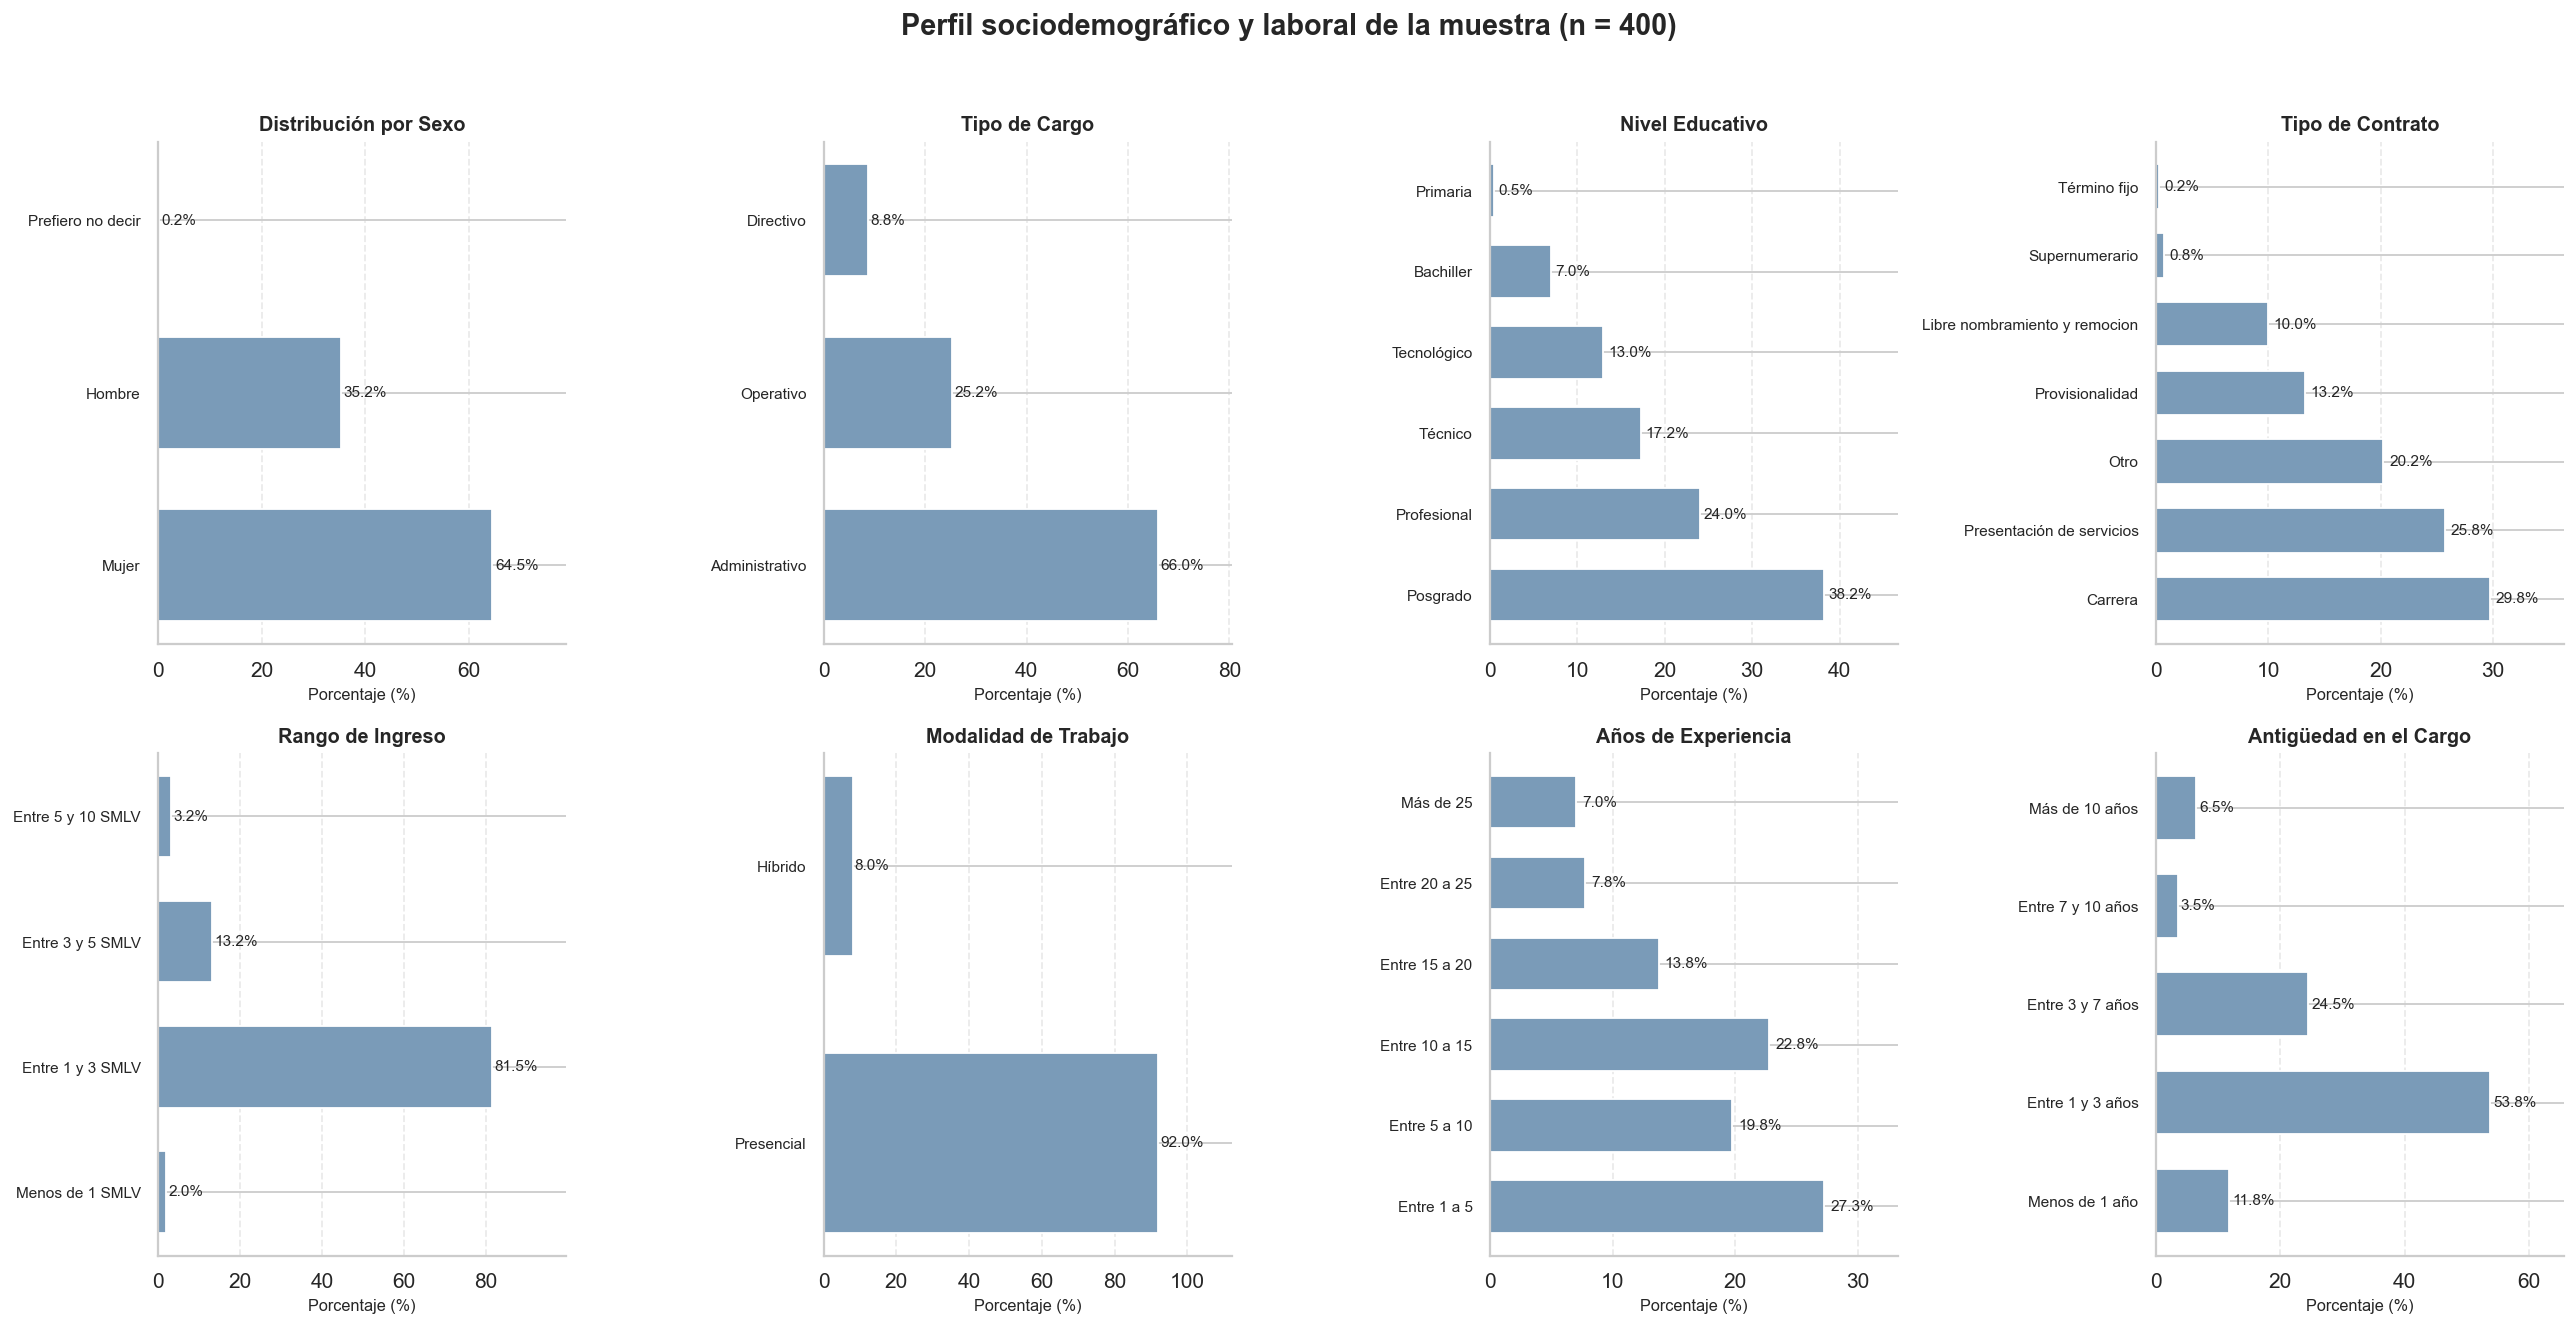

In [13]:
# Panel 2×4 de variables sociodemográficas
vars_plot = [
    ('Sexo',              'Distribución por Sexo'),
    ('Tipo_Cargo',        'Tipo de Cargo'),
    ('Nivel_Educativo',   'Nivel Educativo'),
    ('Tipo_Contrato',     'Tipo de Contrato'),
    ('Ingreso',           'Rango de Ingreso'),
    ('Modalidad',         'Modalidad de Trabajo'),
    ('Años_Experiencia',  'Años de Experiencia'),
    ('Antiguedad_Cargo',  'Antigüedad en el Cargo'),
]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle(
    'Perfil sociodemográfico y laboral de la muestra (n = 400)',
    fontsize=16, fontweight='bold', y=1.02
)
axes = axes.flatten()

ordenes = {
    'Ingreso': ['Menos de 1 SMLV', 'Entre 1 y 3 SMLV', 'Entre 3 y 5 SMLV', 'Entre 5 y 10 SMLV'],
    'Años_Experiencia': ['Entre 1 a 5', 'Entre 5 a 10', 'Entre 10 a 15', 'Entre 15 a 20', 'Entre 20 a 25', 'Más de 25'],
    'Antiguedad_Cargo': ['Menos de 1 año', 'Entre 1 y 3 años', 'Entre 3 y 7 años', 'Entre 7 y 10 años', 'Más de 10 años'],
}

for ax, (var, titulo) in zip(axes, vars_plot):
    if var not in df.columns:
        ax.set_visible(False)
        continue

    orden = ordenes.get(var, None)
    counts = df[var].value_counts()
    if orden:
        orden_valido = [o for o in orden if o in counts.index]
        counts = counts.reindex(orden_valido)
    else:
        counts = counts.sort_values(ascending=False)

    pct = counts / len(df) * 100

    bars = ax.barh(counts.index, pct.values, color=COLOR_NEUTRO,
                   edgecolor='white', height=0.65)

    for bar, val in zip(bars, pct.values):
        ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
                f'{val:.1f}%', va='center', ha='left', fontsize=8.5)

    ax.set_title(titulo, fontsize=11, fontweight='bold', pad=6)
    ax.set_xlabel('Porcentaje (%)', fontsize=9)
    ax.set_xlim(0, pct.max() * 1.22)
    ax.tick_params(axis='y', labelsize=8.5)
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Interpretación:** El panel revela que el perfil predominante de la muestra es una trabajadora o trabajador del sector público, con cargo administrativo, nivel de educación profesional, contrato de carrera o prestación de servicios, ingreso entre 1 y 3 SMLV, modalidad presencial, y entre 1 y 10 años de experiencia. Este perfil es consistente con la composición típica de organizaciones públicas colombianas y enmarca el análisis de bienestar en un contexto institucional con alta rigidez contractual.

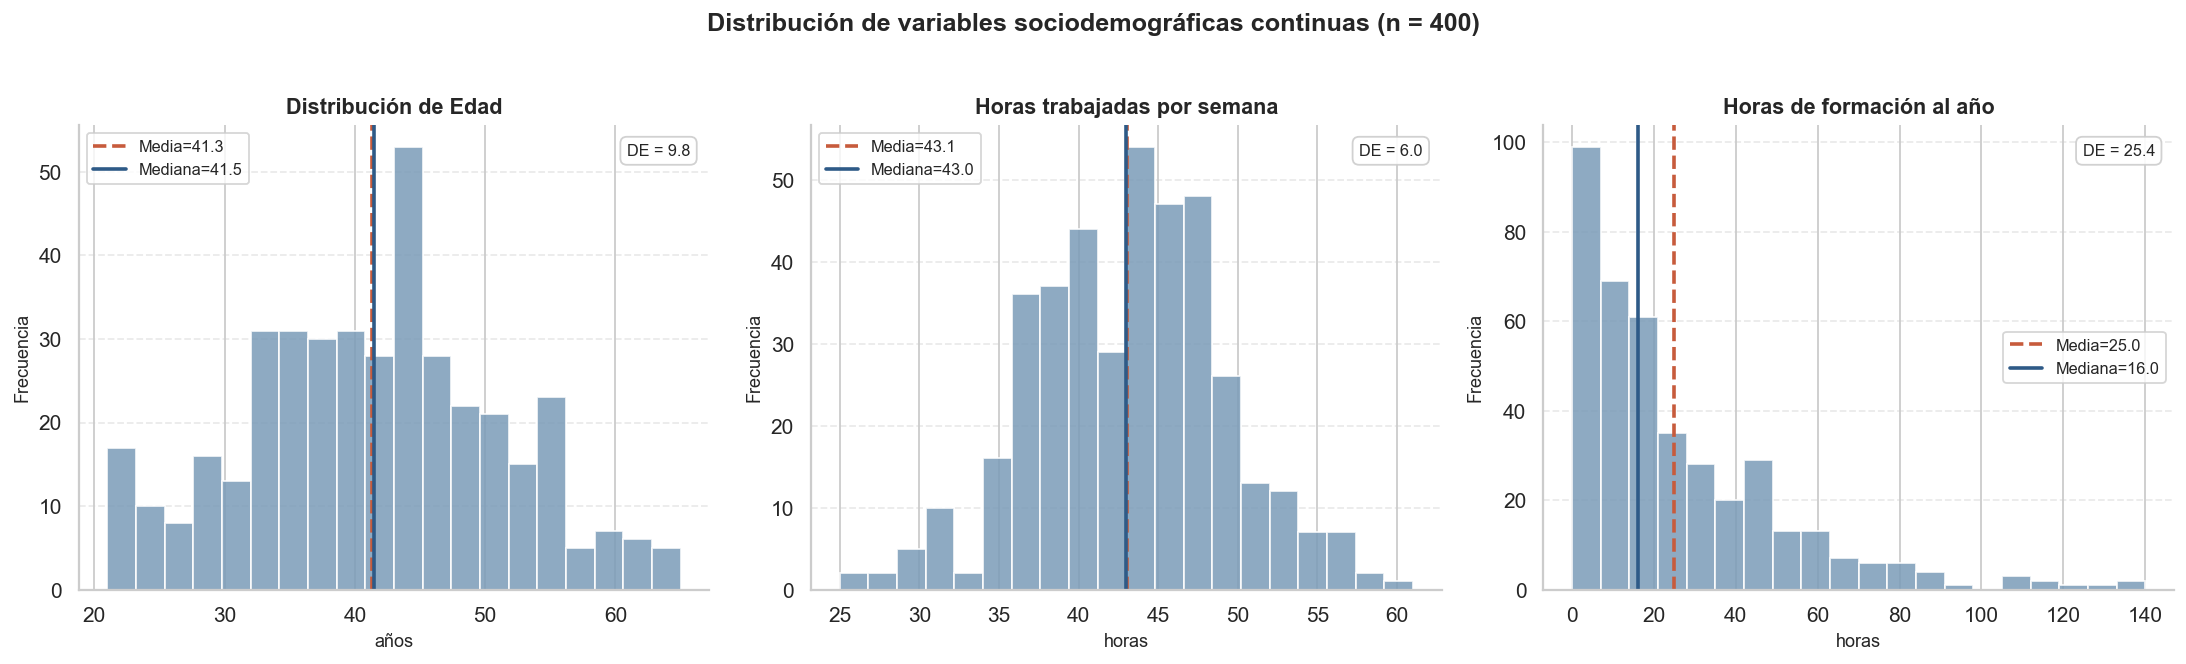

In [14]:
# Variables continuas (Edad, Horas de trabajo, Horas de formación)
vars_cont_plot = [
    ('Edad',            'Distribución de Edad', 'años'),
    ('Horas_Semana',    'Horas trabajadas por semana', 'horas'),
    ('Horas_Formacion', 'Horas de formación al año', 'horas'),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Distribución de variables sociodemográficas continuas (n = 400)',
             fontsize=14, fontweight='bold', y=1.02)

for ax, (var, titulo, unidad) in zip(axes, vars_cont_plot):
    serie = df[var].dropna()
    media  = serie.mean()
    mediana = serie.median()
    de     = serie.std()

    ax.hist(serie, bins=20, color=COLOR_NEUTRO, edgecolor='white', alpha=0.85)
    ax.axvline(media,   color='#C75B3C', lw=2, linestyle='--', label=f'Media={media:.1f}')
    ax.axvline(mediana, color='#2E5A87', lw=2, linestyle='-',  label=f'Mediana={mediana:.1f}')

    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel(unidad, fontsize=10)
    ax.set_ylabel('Frecuencia', fontsize=10)
    ax.legend(fontsize=9)

    texto = f'DE = {de:.1f}'
    ax.text(0.97, 0.96, texto, transform=ax.transAxes,
            ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#ccc', alpha=0.9))

    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## **Sección 2 - Preparación de Variables**

### 2.1 Codificación de escalas

La conversión transforma las respuestas categóricas en valores numéricos enteros usando reglas de escala específicas para cada grupo de variables. Se definen cuatro diccionarios de mapeo:

- `map_5_standard` (1-5: "Nunca", "Rara vez", "Algunas veces", "Frecuentemente", "Siempre") para **CT, PT, CL, AC, CR, CoR, GC y SM**.
- `map_bu` (1-5, con "Raramente" y "A menudo" como categorías intermedias) para **BU**.
- `map_7` (1-7: de "Nunca" a "Siempre", con frecuencias ampliadas) para **SOM y DL**.
- `map_likert_7` (1-7: de "Muy en desacuerdo" a "Muy de acuerdo") para **SAT, IR, FT y TF**.

Las columnas **BP1-BP10** ya vienen codificadas numéricamente (1–7) en el dataset original, por lo que no requieren mapeo.

In [15]:
# CODIFICACIÓN DE ESCALAS

# Diccionarios de mapeo
# CT, PT, CL, AC, CR, CoR, GC, SM
map_5_standard = {            
    'Nunca': 1, 'Rara vez': 2, 'Algunas veces': 3,
    'Frecuentemente': 4, 'Siempre': 5
}
# BU (Burnout)
map_bu = {                    
    'Nunca': 1, 'Raramente': 2, 'Algunas veces': 3,
    'A menudo': 4, 'Siempre': 5
}
# SOM, DL
map_7 = {         
    'Nunca': 1, 'Raramente': 2, 'Ocasionalmente': 3, 'Algunas veces': 4,
    'Frecuentemente': 5, 'Casi siempre': 6, 'Siempre': 7
}
# SAT, IR, FT, TF
map_likert_7 = {
    'Muy en desacuerdo': 1, 'Moderadamente en desacuerdo': 2,
    'Algo en desacuerdo': 3, 'Ni de acuerdo ni en desacuerdo': 4,
    'Algo de acuerdo': 5, 'Moderadamente de acuerdo': 6, 'Muy de acuerdo': 7
}

# Grupos de ítems por tipo de escala
grupos_5   = ['CT', 'PT', 'CL', 'AC', 'CR', 'CoR', 'GC', 'SM']
grupos_7   = ['SOM', 'DL']
grupos_lik = ['SAT', 'IR', 'FT', 'TF']

def items_de(prefijos):
    cols = []
    for c in df.columns:
        for g in prefijos:
            if c.startswith(g) and c[len(g):].isdigit():
                cols.append(c)
    return cols

items_5   = items_de(grupos_5)
items_bu  = items_de(['BU'])
items_7   = items_de(grupos_7)
items_lik = items_de(grupos_lik)

# Aplicar el mapeo
for c in items_5:   df[c] = df[c].map(map_5_standard)
for c in items_bu:  df[c] = df[c].map(map_bu)
for c in items_7:   df[c] = df[c].map(map_7)
for c in items_lik: df[c] = df[c].map(map_likert_7)

# Verificación: no deben quedar valores sin reconocer
items_codificados = items_5 + items_bu + items_7 + items_lik
n_nan = df[items_codificados].isna().sum().sum()

if n_nan == 0:
    print(f'Codificación correcta: {len(items_codificados)} ítems convertidos a numérico, 0 valores no reconocidos.')
else:
    print(f'ATENCIÓN: {n_nan} valores no reconocidos quedaron como NaN. Revisar los diccionarios de mapeo.')

Codificación correcta: 81 ítems convertidos a numérico, 0 valores no reconocidos.


**Inversión del ítem IR1.** El ítem IR1 está redactado en dirección opuesta al constructo de Intención de Retiro (mide *deseo de permanencia*, no *deseo de
abandono*). 

Antes de construir el promedio de la dimensión IR es necesario invertirlo con la fórmula `IR1_inv = 8 - IR1`, válida para una escala Likert 1-7. El criterio estadístico que justifica esta decisión se documenta y verifica en detalle en la sección 2.2.

In [16]:
# INVERSIÓN DEL ÍTEM IR1
corr_antes = df[['IR1', 'IR2', 'IR3', 'IR4']].corr().loc['IR1', ['IR2', 'IR3', 'IR4']]
print('Correlaciones de IR1 ANTES de invertir:')
print(corr_antes.round(2).to_string())

# Inversión: escala Likert 1-7  →  IR1_inv = 8 - IR1
df['IR1'] = 8 - df['IR1']

corr_despues = df[['IR1', 'IR2', 'IR3', 'IR4']].corr().loc['IR1', ['IR2', 'IR3', 'IR4']]
print('\nCorrelaciones de IR1 DESPUÉS de invertir:')
print(corr_despues.round(2).to_string())
print('\nIR1 invertido. Las correlaciones pasaron de negativas a positivas, confirmando que ahora apunta en la misma dirección del constructo.')

Correlaciones de IR1 ANTES de invertir:
IR2   -0.84
IR3   -0.87
IR4   -0.84

Correlaciones de IR1 DESPUÉS de invertir:
IR2    0.84
IR3    0.87
IR4    0.84

IR1 invertido. Las correlaciones pasaron de negativas a positivas, confirmando que ahora apunta en la misma dirección del constructo.


### 2.2 Construcción de variables promedio por dimensión

El código toma las variables numéricas organizadas por dimensiones psicosociales (como **CT** - Control del trabajo, **CL** - Compromiso del líder, **SAT** - Satisfacción, **BU** - Burnout, **SOM** - Somatización y **DL** - Desgaste laboral, entre otras). Para cada dimensión identifica automáticamente los ítems que la componen (por ejemplo, los 3 ítems de **CT** o los 12 de **BU**) y calcula el promedio por fila de todos los valores disponibles, ignorando los faltantes.

Como resultado se crea una nueva variable por cada dimensión con el sufijo `_prom` (ej. `CT_prom`, `SAT_prom`, `BU_prom`), manteniendo intactas las variables originales. Esto permite resumir constructos complejos en una sola puntuación media por persona.

In [17]:
# CONSTRUCCIÓN DE LAS 16 VARIABLES PROMEDIO POR DIMENSIÓN
dimensiones = {
    'CT':  ['CT1', 'CT2', 'CT3'],
    'PT':  ['PT1', 'PT2', 'PT3', 'PT4'],
    'CL':  ['CL1', 'CL2', 'CL3', 'CL4', 'CL5', 'CL6', 'CL7'],
    'AC':  ['AC1', 'AC2', 'AC3'],
    'CR':  ['CR1', 'CR2', 'CR3', 'CR4'],
    'CoR': ['CoR1', 'CoR2', 'CoR3'],
    'GC':  ['GC1', 'GC2', 'GC3', 'GC4'],
    'SM':  ['SM1', 'SM2', 'SM3', 'SM4', 'SM5'],
    'SAT': ['SAT1', 'SAT2', 'SAT3', 'SAT4', 'SAT5', 'SAT6', 'SAT7', 'SAT8', 'SAT9'],
    'IR':  ['IR1', 'IR2', 'IR3', 'IR4'],   # IR1 ya fue invertido en 2.1
    'FT':  ['FT1', 'FT2', 'FT3', 'FT4', 'FT5'],
    'TF':  ['TF1', 'TF2', 'TF3', 'TF4', 'TF5'],
    'BU':  ['BU1', 'BU2', 'BU3', 'BU4', 'BU5', 'BU6', 'BU7', 'BU8', 'BU9', 'BU10', 'BU11', 'BU12'],
    'BP':  ['BP1', 'BP2', 'BP3', 'BP4', 'BP5', 'BP6', 'BP7', 'BP8', 'BP9', 'BP10'],
    'SOM': ['SOM1', 'SOM2', 'SOM3', 'SOM4', 'SOM5'],
    'DL':  ['DL1', 'DL2', 'DL3', 'DL4', 'DL5', 'DL6', 'DL7', 'DL8'],
}

for dim, items in dimensiones.items():
    items_existentes = [it for it in items if it in df.columns]
    if not items_existentes:
        print(f'Ningún ítem encontrado para {dim}. Se omite.')
        continue
    df[dim + '_prom'] = df[items_existentes].mean(axis=1, skipna=True)
    print(f'Creada variable {dim}_prom (promedio de {len(items_existentes)} ítems)')

columnas_prom = [d + '_prom' for d in dimensiones if (d + '_prom') in df.columns]
print(f'\nSe crearon {len(columnas_prom)} variables promedio. Primeras filas:')
display(df[['ID'] + columnas_prom].head(10))

Creada variable CT_prom (promedio de 3 ítems)
Creada variable PT_prom (promedio de 4 ítems)
Creada variable CL_prom (promedio de 7 ítems)
Creada variable AC_prom (promedio de 3 ítems)
Creada variable CR_prom (promedio de 4 ítems)
Creada variable CoR_prom (promedio de 3 ítems)
Creada variable GC_prom (promedio de 4 ítems)
Creada variable SM_prom (promedio de 5 ítems)
Creada variable SAT_prom (promedio de 9 ítems)
Creada variable IR_prom (promedio de 4 ítems)
Creada variable FT_prom (promedio de 5 ítems)
Creada variable TF_prom (promedio de 5 ítems)
Creada variable BU_prom (promedio de 12 ítems)
Creada variable BP_prom (promedio de 10 ítems)
Creada variable SOM_prom (promedio de 5 ítems)
Creada variable DL_prom (promedio de 8 ítems)

Se crearon 16 variables promedio. Primeras filas:


,ID,CT_prom,PT_prom,CL_prom,AC_prom,CR_prom,CoR_prom,GC_prom,SM_prom,SAT_prom,IR_prom,FT_prom,TF_prom,BU_prom,BP_prom,SOM_prom,DL_prom
0,1,2.333333,3.00,2.428571,4.000000,4.75,2.000000,2.25,2.4,5.777778,2.25,1.2,1.6,1.833333,5.2,2.0,2.000
1,2,4.000000,2.50,2.857143,4.333333,4.50,2.333333,1.75,2.6,5.000000,4.00,1.6,4.8,1.833333,5.2,2.4,1.125
2,3,3.000000,3.25,4.428571,2.333333,4.50,2.000000,3.75,2.2,6.222222,1.00,3.4,2.2,2.083333,5.6,4.6,1.250
3,4,3.333333,1.50,3.142857,2.666667,4.50,1.666667,3.50,2.0,7.000000,2.00,2.4,2.4,2.250000,6.3,3.0,1.125
4,5,2.000000,3.75,3.428571,3.000000,3.50,3.666667,3.25,5.0,4.888889,2.25,1.8,1.8,4.333333,3.9,4.0,4.125
5,6,4.333333,2.50,2.428571,4.000000,4.50,2.333333,2.25,2.2,6.111111,1.50,1.6,2.4,1.333333,6.0,3.2,3.875
6,7,3.666667,2.75,4.571429,5.000000,4.75,2.666667,4.25,2.8,6.333333,1.25,1.0,3.8,1.166667,5.2,2.8,1.375
7,8,3.000000,3.75,3.571429,3.000000,4.25,3.000000,4.00,4.0,5.333333,3.75,2.6,6.4,2.666667,4.9,3.4,5.000
8,9,1.000000,4.75,1.142857,4.333333,3.50,3.666667,1.50,2.8,2.888889,7.00,2.4,5.6,4.250000,2.8,4.8,6.875
9,10,4.666667,1.50,3.285714,4.333333,3.75,3.333333,3.00,1.2,4.555556,2.25,1.8,4.6,2.500000,5.6,1.2,1.000


#### Criterio de inversión del ítem IR1

El siguiente gráfico documenta la evidencia que sustenta la inversión aplicada en la sección 2.1.

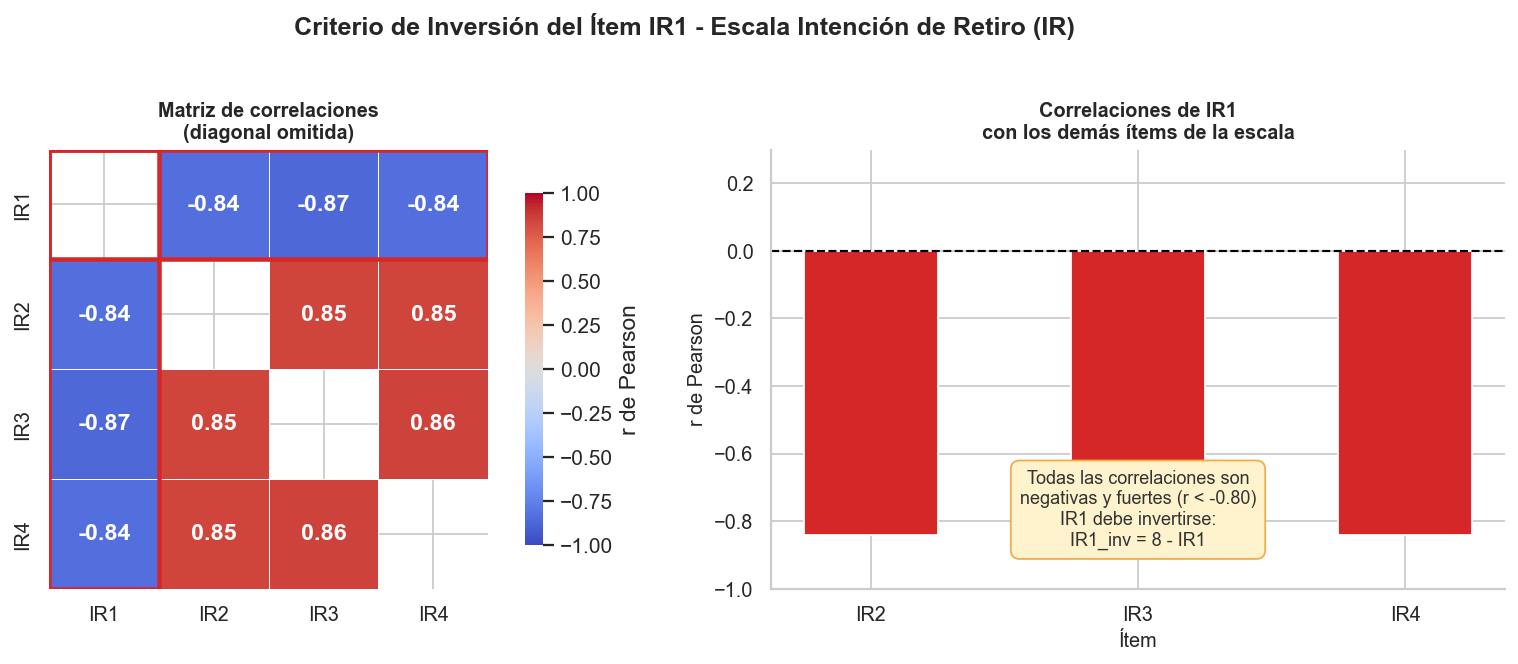

In [20]:
# Reconstrucción del IR1 ORIGINAL (des-invertido) solo para graficar el diagnóstico.
df_ir = pd.DataFrame({
    'IR1': 8 - df['IR1'],   # vuelve al valor original
    'IR2': df['IR2'],
    'IR3': df['IR3'],
    'IR4': df['IR4'],
}).dropna()

# Matriz de correlaciones
corr_matrix = df_ir.corr(method='pearson')

# Figura con dos paneles
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(
    'Criterio de Inversión del Ítem IR1 - Escala Intención de Retiro (IR)',
    fontsize=14, fontweight='bold', y=1.02
)

# Panel izquierdo: Heatmap
mascara = np.eye(len(corr_matrix), dtype=bool)
sns.heatmap(
    corr_matrix, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm',
    center=0, vmin=-1, vmax=1, linewidths=0.5, linecolor='white', square=True,
    ax=axes[0], annot_kws={'size': 13, 'weight': 'bold'},
    cbar_kws={'shrink': 0.8, 'label': 'r de Pearson'},
)
axes[0].add_patch(mpatches.FancyBboxPatch(
    (0, 0), 4, 1, boxstyle='square,pad=0', linewidth=2.5,
    edgecolor='#d62728', facecolor='none', zorder=5))
axes[0].add_patch(mpatches.FancyBboxPatch(
    (0, 0), 1, 4, boxstyle='square,pad=0', linewidth=2.5,
    edgecolor='#d62728', facecolor='none', zorder=5))
axes[0].set_title('Matriz de correlaciones\n(diagonal omitida)',
                  fontsize=11, fontweight='bold')
axes[0].tick_params(axis='both', labelsize=11)

# Panel derecho: Barras de correlación de IR1
r_vals = corr_matrix.loc['IR1', ['IR2', 'IR3', 'IR4']]
bars = axes[1].bar(r_vals.index, r_vals.values, color='#d62728',
                   edgecolor='white', width=0.5)
axes[1].axhline(0, color='black', linewidth=1.2, linestyle='--')
for bar, val in zip(bars, r_vals.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, val + 0.04,
                 f'r = {val:.2f}', ha='center', va='bottom',
                 fontsize=12, fontweight='bold', color='#d62728')
axes[1].set_ylim(-1, 0.3)
axes[1].set_title('Correlaciones de IR1\ncon los demás ítems de la escala',
                  fontsize=11, fontweight='bold')
axes[1].set_ylabel('r de Pearson', fontsize=11)
axes[1].set_xlabel('Ítem', fontsize=11)
axes[1].tick_params(axis='both', labelsize=11)
axes[1].text(
    0.5, 0.18,
    'Todas las correlaciones son\nnegativas y fuertes (r < -0.80)\n'
    'IR1 debe invertirse:\nIR1_inv = 8 - IR1',
    transform=axes[1].transAxes, ha='center', va='center',
    fontsize=10, color='#333333',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff3cd', edgecolor='#f0ad4e'))

plt.tight_layout()
plt.show()

La matriz de correlaciones de Pearson evidencia que el ítem IR1 está redactado en dirección opuesta al constructo de Intención de Retiro. En su forma original, IR1 presenta correlaciones **negativas y fuertes** con los tres ítems restantes de la escala (r = −0.84 con IR2, r = −0.87 con IR3 y r = −0.84 con IR4), mientras que IR2, IR3 e IR4 correlacionan positivamente entre sí con magnitudes similares, conformando un bloque coherente que apunta en la dirección del constructo. Este patrón simétrico, un único ítem que se opone sistemáticamente a los demás con magnitudes equivalentes, es la huella estadística característica de un ítem inverso dentro de una escala unidimensional.

En consecuencia se estableció como criterio que IR1 debe invertirse antes de cualquier análisis posterior, aplicando la fórmula `IR1_inv = 8 - IR1`, válida para una escala Likert de 1 a 7. Esta inversión ya fue aplicada en la sección 2.1; tras ella, las cuatro correlaciones inter-ítem se vuelven positivas y de magnitud similar (≈ +0.84 a +0.87), lo que confirma empíricamente el éxito de la transformación.

### 2.3 Verificación de rangos

In [21]:
escalas_esperadas = {
    'CT_prom':  (1, 5), 'PT_prom':  (1, 5), 'CL_prom':  (1, 5),
    'AC_prom':  (1, 5), 'CR_prom':  (1, 5), 'CoR_prom': (1, 5),
    'GC_prom':  (1, 5), 'SM_prom':  (1, 5), 'BU_prom':  (1, 5),
    'SAT_prom': (1, 7), 'IR_prom':  (1, 7), 'FT_prom':  (1, 7),
    'TF_prom':  (1, 7), 'BP_prom':  (1, 7), 'SOM_prom': (1, 7),
    'DL_prom':  (1, 7),
}

filas = []
for dim, (lim_inf, lim_sup) in escalas_esperadas.items():
    serie = df[dim].dropna()
    minimo, maximo, media = serie.min(), serie.max(), serie.mean()
    n_fuera = ((serie < lim_inf) | (serie > lim_sup)).sum()
    coherente = (minimo >= lim_inf) and (maximo <= lim_sup)
    filas.append({
        'Dimensión': dim, 'Escala teórica': f'[{lim_inf}, {lim_sup}]',
        'Mín observado': round(minimo, 3), 'Máx observado': round(maximo, 3),
        'Media': round(media, 3), 'Fuera de rango': n_fuera,
        '¿Coherente?': 'Sí' if coherente else 'No'
    })

tabla_verificacion = pd.DataFrame(filas)
print(tabla_verificacion.to_string(index=False))

total_dims  = len(tabla_verificacion)
dims_ok     = (tabla_verificacion['¿Coherente?'] == 'Sí').sum()
total_fuera = tabla_verificacion['Fuera de rango'].sum()
print("")
print(f'Dimensiones coherentes con su escala: {dims_ok}/{total_dims}')
print(f'Total de valores promedio fuera de rango: {total_fuera}')
print("")

Dimensión Escala teórica  Mín observado  Máx observado  Media  Fuera de rango ¿Coherente?
  CT_prom         [1, 5]          1.000            5.0  2.959               0          Sí
  PT_prom         [1, 5]          1.000            5.0  2.988               0          Sí
  CL_prom         [1, 5]          1.000            5.0  3.222               0          Sí
  AC_prom         [1, 5]          1.333            5.0  3.713               0          Sí
  CR_prom         [1, 5]          2.500            5.0  4.394               0          Sí
 CoR_prom         [1, 5]          1.000            5.0  2.511               0          Sí
  GC_prom         [1, 5]          1.000            5.0  3.051               0          Sí
  SM_prom         [1, 5]          1.000            5.0  2.941               0          Sí
  BU_prom         [1, 5]          1.000            5.0  2.359               0          Sí
 SAT_prom         [1, 7]          1.444            7.0  5.036               0          Sí
  IR_prom 

El bloque parte del diccionario `escalas_esperadas`, que asocia cada variable promedio (`CT_prom`, …, `DL_prom`) con su rango teórico: las nueve dimensiones medidas en frecuencia (`CT`, `PT`, `CL`, `AC`, `CR`, `CoR`, `GC`, `SM`, `BU`) están acotadas a `[1, 5]`, mientras que las siete dimensiones de acuerdo, intención, conflicto y bienestar (`SAT`, `IR`, `FT`, `TF`, `BP`, `SOM`, `DL`) lo están a `[1, 7]`. Para cada dimensión se calcularon mínimo, máximo y media, y se contabilizó cuántas observaciones caen fuera del rango teórico. La bandera de coherencia se vuelve verdadera solo cuando el mínimo observado es ≥ al límite inferior y el máximo observado es ≤ al límite superior.

Al ejecutar el código sobre las 400 encuestas, las **16 dimensiones cumplen con su escala teórica y no existe ni un solo promedio fuera de rango**. El caso de `IR_prom` es coherente porque el promedio ya incluye el ítem invertido `IR1_inv = 8 − IR1`. Esto valida que la codificación numérica, la inversión de IR1 y el cálculo de promedios quedaron correctamente aplicados antes de pasar al análisis univariado.

## **Sección 3 - Análisis Univariado**

In [22]:
# METADATOS DE LAS 16 DIMENSIONES
dimensiones_info = {
    'CT':  ('Recurso',   '1–5',  'Control del trabajo'),
    'PT':  ('Demanda',   '1–5',  'Presión del tiempo'),
    'CL':  ('Recurso',   '1–5',  'Compromiso del líder'),
    'AC':  ('Recurso',   '1–5',  'Apoyo de compañeros'),
    'CR':  ('Recurso',   '1–5',  'Claridad de rol'),
    'CoR': ('Demanda',   '1–5',  'Conflicto de rol'),
    'GC':  ('Recurso',   '1–5',  'Gestión del cambio'),
    'SM':  ('Resultado', '1–5',  'Salud mental organizacional'),
    'SAT': ('Resultado', '1–7',  'Satisfacción / Engagement'),
    'IR':  ('Demanda*',  '1–7',  'Intención de retiro'),
    'FT':  ('Demanda',   '1–7',  'Conflicto Familia→Trabajo'),
    'TF':  ('Demanda',   '1–7',  'Conflicto Trabajo→Familia'),
    'BU':  ('Resultado', '1–5',  'Burnout / Agotamiento'),
    'BP':  ('Resultado', '1–7',  'Bienestar percibido'),
    'SOM': ('Resultado', '1–7',  'Somatización'),
    'DL':  ('Resultado', '1–7',  'Desgaste laboral'),
}

dims = list(dimensiones_info.keys())
prom_cols = [d + '_prom' for d in dims]

# Escala teórica máxima de cada dimensión (para normalizar)
escalas_max = {
    'CT': 5, 'PT': 5, 'CL': 5, 'AC': 5, 'CR': 5, 'CoR': 5, 'GC': 5, 'SM': 5,
    'BU': 5, 'SAT': 7, 'IR': 7, 'FT': 7, 'TF': 7, 'BP': 7, 'SOM': 7, 'DL': 7,
}

def color_dim(dim):
    tipo = dimensiones_info[dim][0]
    if tipo == 'Recurso':  return COLOR_RECURSO
    if 'Demanda' in tipo:  return COLOR_DEMANDA
    return COLOR_RESULTADO

print(f'Metadatos listos para {len(dims)} dimensiones psicosociales.')

Metadatos listos para 16 dimensiones psicosociales.


### 3.1 Estadísticos descriptivos

In [24]:
# Tabla de estadísticos descriptivos de las 16 dimensiones
filas = []
for dim in dims:
    col = dim + '_prom'
    if col not in df.columns:
        continue
    serie = df[col].dropna()
    tipo, escala, desc = dimensiones_info[dim]

    # Test de normalidad Shapiro-Wilk
    _, p_sw = stats.shapiro(serie)
    normal = 'Sí' if p_sw > 0.05 else 'No'

    filas.append({
        'Dimensión':   dim,        'Descripción': desc,
        'Tipo':        tipo,       'Escala':      escala,
        'n':           int(serie.count()),
        'Media':       round(serie.mean(), 2),
        'Mediana':     round(serie.median(), 2),
        'DE':          round(serie.std(), 2),
        'Mín':         round(serie.min(), 2),
        'Máx':         round(serie.max(), 2),
        'Asimetría':   round(serie.skew(), 2),
        'Curtosis':    round(serie.kurtosis(), 2),
        'Normal (SW)': normal,
        'p-SW':        round(p_sw, 4),
    })

tabla_desc = pd.DataFrame(filas)

print("")
print(f'{"ESTADÍSTICOS DESCRIPTIVOS - 16 DIMENSIONES PSICOSOCIALES"}')
print("")
cols_mostrar = ['Dimensión', 'Descripción', 'Tipo', 'Escala', 'Media', 'Mediana',
                'DE', 'Mín', 'Máx', 'Asimetría', 'Curtosis', 'Normal (SW)']
print(tabla_desc[cols_mostrar].to_string(index=False))
print('\nNota: Normal (SW) = Distribución normal según Shapiro-Wilk (α = 0.05)')


ESTADÍSTICOS DESCRIPTIVOS - 16 DIMENSIONES PSICOSOCIALES

Dimensión                 Descripción      Tipo Escala  Media  Mediana   DE  Mín  Máx  Asimetría  Curtosis Normal (SW)
       CT         Control del trabajo   Recurso    1–5   2.96     3.00 1.21 1.00  5.0       0.02     -1.16          No
       PT          Presión del tiempo   Demanda    1–5   2.99     3.00 1.10 1.00  5.0      -0.02     -1.06          No
       CL        Compromiso del líder   Recurso    1–5   3.22     3.29 0.94 1.00  5.0      -0.12     -0.70          No
       AC         Apoyo de compañeros   Recurso    1–5   3.71     3.67 0.72 1.33  5.0      -0.39     -0.05          No
       CR             Claridad de rol   Recurso    1–5   4.39     4.50 0.46 2.50  5.0      -0.89      1.08          No
      CoR            Conflicto de rol   Demanda    1–5   2.51     2.67 0.77 1.00  5.0       0.04     -0.45          No
       GC          Gestión del cambio   Recurso    1–5   3.05     3.25 0.90 1.00  5.0      -0.11     -0.65  

### 3.2 Distribuciones

Se visualiza la distribución de las 16 dimensiones mediante boxplots normalizados a una escala común 0–100 %, lo que permite compararlas directamente pese a tener escalas teóricas distintas (1–5 y 1–7).

A continuación se examinan la asimetría y la curtosis de cada distribución.

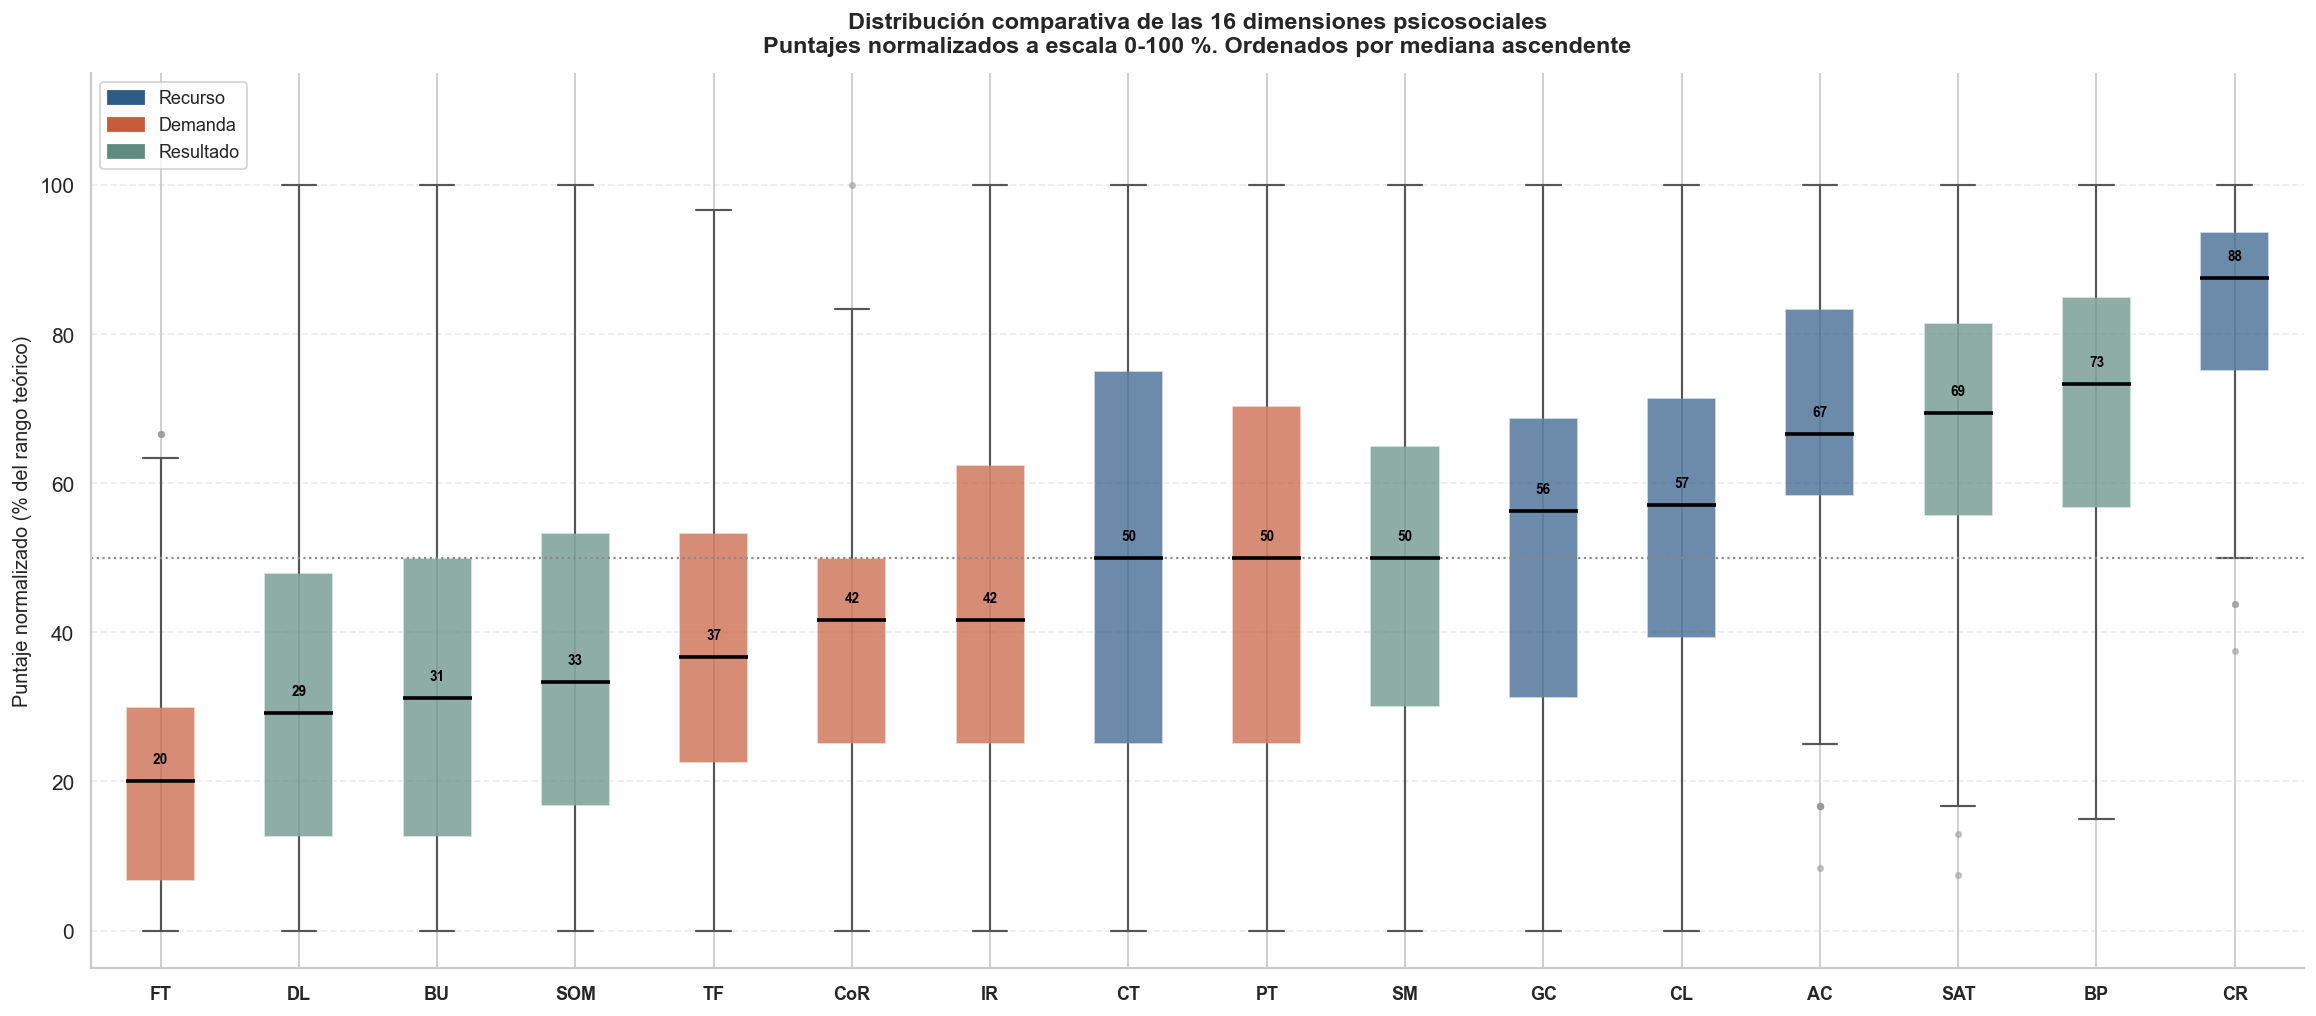

In [25]:
# Boxplots normalizados (0-100 %)
df_norm = pd.DataFrame()
for dim in dims:
    col = dim + '_prom'
    if col in df.columns:
        max_escala = escalas_max.get(dim, 7)
        df_norm[dim] = (df[col] - 1) / (max_escala - 1) * 100

orden_mediana = df_norm.median().sort_values().index.tolist()
df_plot = df_norm[orden_mediana]
paleta_box = [color_dim(d) for d in orden_mediana]

fig, ax = plt.subplots(figsize=(18, 8))
bp = ax.boxplot(
    [df_plot[dim].dropna().values for dim in orden_mediana],
    patch_artist=True, vert=True, notch=False,
    medianprops={'color': 'black', 'linewidth': 2},
    whiskerprops={'color': '#555', 'linewidth': 1.2},
    capprops={'color': '#555', 'linewidth': 1.2},
    flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': '#999',
                'markeredgecolor': '#999', 'alpha': 0.5},
)
for patch, color in zip(bp['boxes'], paleta_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
    patch.set_edgecolor('white')

for j, dim in enumerate(orden_mediana):
    mdn = df_plot[dim].median()
    ax.text(j + 1, mdn + 2, f'{mdn:.0f}', ha='center', va='bottom',
            fontsize=7.5, fontweight='bold', color='black')

ax.axhline(50, color='#888', linestyle=':', linewidth=1.2, label='50 % de la escala')
ax.set_xticks(range(1, len(orden_mediana) + 1))
ax.set_xticklabels(orden_mediana, fontsize=10, fontweight='bold')
ax.set_ylabel('Puntaje normalizado (% del rango teórico)', fontsize=11)
ax.set_ylim(-5, 115)

parche_r  = mpatches.Patch(color=COLOR_RECURSO,   label='Recurso')
parche_d  = mpatches.Patch(color=COLOR_DEMANDA,   label='Demanda')
parche_rs = mpatches.Patch(color=COLOR_RESULTADO, label='Resultado')
ax.legend(handles=[parche_r, parche_d, parche_rs], loc='upper left', fontsize=10)

ax.set_title(
    'Distribución comparativa de las 16 dimensiones psicosociales\n'
    'Puntajes normalizados a escala 0-100 %. Ordenados por mediana ascendente',
    fontsize=13, fontweight='bold', pad=12
)
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

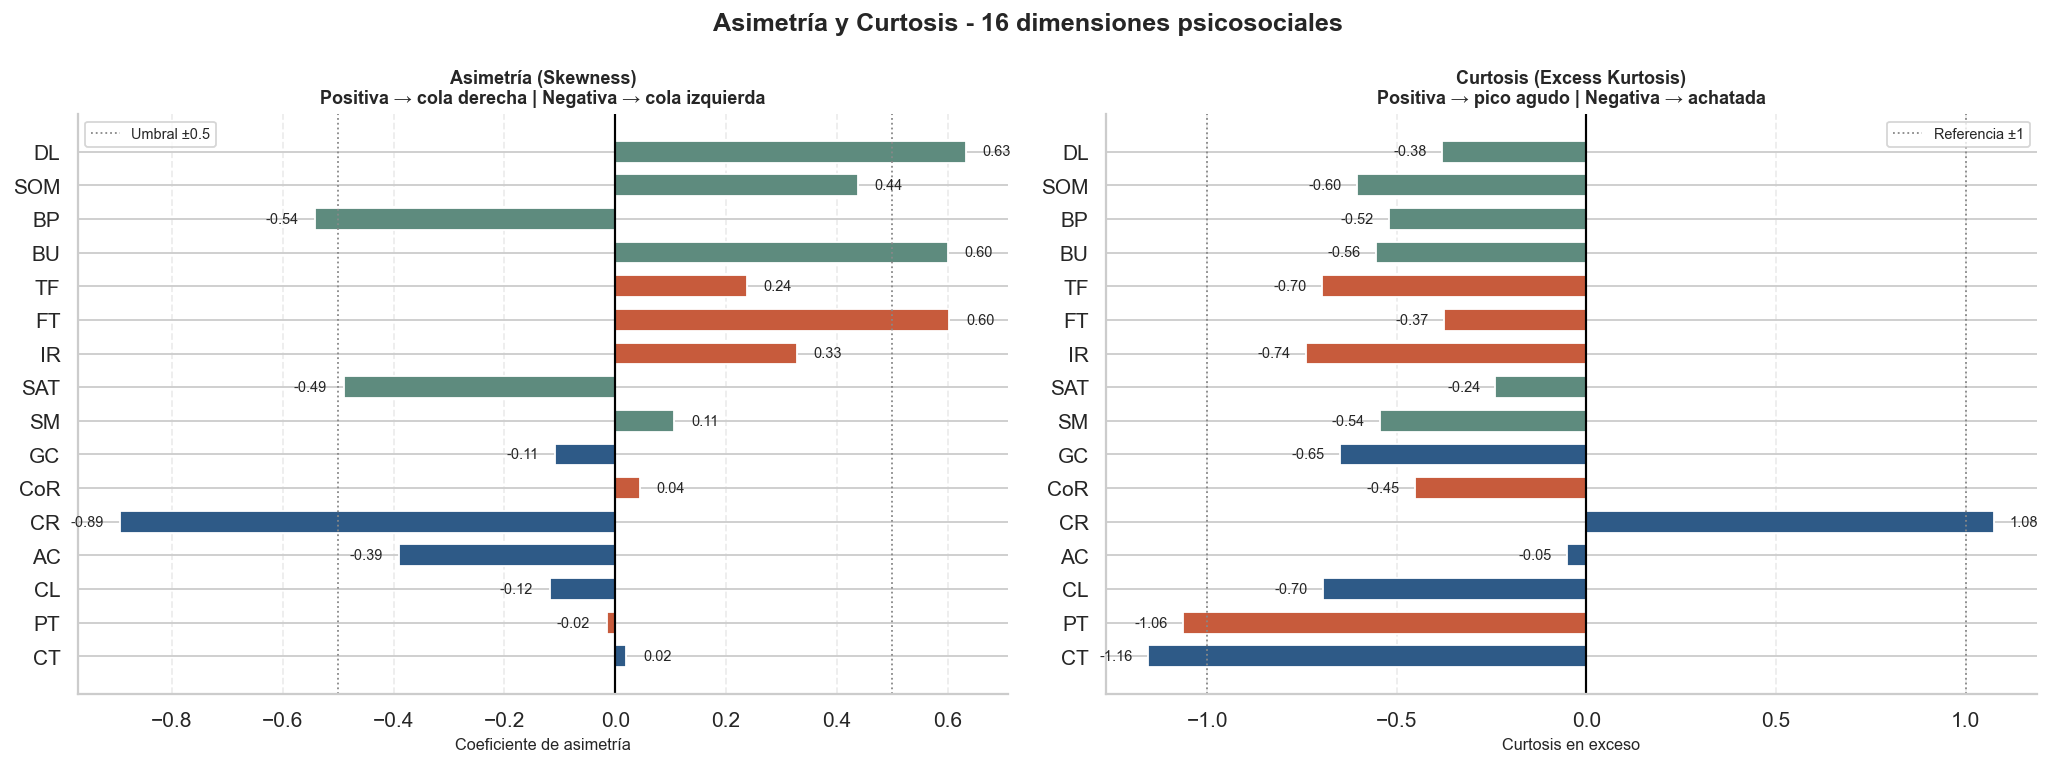

In [26]:
# Asimetría y curtosis de las 16 dimensiones
skew_vals  = [df[d + '_prom'].skew()     for d in dims if d + '_prom' in df.columns]
kurt_vals  = [df[d + '_prom'].kurtosis() for d in dims if d + '_prom' in df.columns]
dims_valid = [d for d in dims if d + '_prom' in df.columns]
colores_v  = [color_dim(d) for d in dims_valid]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Asimetría y Curtosis - 16 dimensiones psicosociales',
             fontsize=14, fontweight='bold')

# Panel 1: Asimetría
ax = axes[0]
bars = ax.barh(dims_valid, skew_vals, color=colores_v, edgecolor='white', height=0.65)
ax.axvline(0,    color='black', lw=1.2, linestyle='-')
ax.axvline(-0.5, color='#888',  lw=1,   linestyle=':', label='Umbral ±0.5')
ax.axvline( 0.5, color='#888',  lw=1,   linestyle=':')
for bar, val in zip(bars, skew_vals):
    x_pos = val + 0.03 if val >= 0 else val - 0.03
    ax.text(x_pos, bar.get_y() + bar.get_height() / 2, f'{val:.2f}',
            va='center', ha='left' if val >= 0 else 'right', fontsize=8)
ax.set_title('Asimetría (Skewness)\nPositiva → cola derecha | Negativa → cola izquierda',
             fontsize=10, fontweight='bold')
ax.set_xlabel('Coeficiente de asimetría', fontsize=9)
ax.legend(fontsize=8)
ax.grid(axis='x', linestyle='--', alpha=0.35)
ax.set_axisbelow(True)

# Panel 2: Curtosis
ax = axes[1]
bars = ax.barh(dims_valid, kurt_vals, color=colores_v, edgecolor='white', height=0.65)
ax.axvline(0,  color='black', lw=1.2, linestyle='-')
ax.axvline(-1, color='#888',  lw=1,   linestyle=':', label='Referencia ±1')
ax.axvline( 1, color='#888',  lw=1,   linestyle=':')
for bar, val in zip(bars, kurt_vals):
    x_pos = val + 0.04 if val >= 0 else val - 0.04
    ax.text(x_pos, bar.get_y() + bar.get_height() / 2, f'{val:.2f}',
            va='center', ha='left' if val >= 0 else 'right', fontsize=8)
ax.set_title('Curtosis (Excess Kurtosis)\nPositiva → pico agudo | Negativa → achatada',
             fontsize=10, fontweight='bold')
ax.set_xlabel('Curtosis en exceso', fontsize=9)
ax.legend(fontsize=8)
ax.grid(axis='x', linestyle='--', alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [27]:
# Interpretación de asimetría y curtosis por dimensión
print(f'{"INTERPRETACIÓN DE ASIMETRÍA Y CURTOSIS POR DIMENSIÓN"}')
print("")

# Dirección del riesgo: alto/bajo = qué extremo es malo
direccion_riesgo = {
    'CT': 'bajo', 'PT': 'alto', 'CL': 'bajo', 'AC': 'bajo', 'CR': 'bajo',
    'CoR': 'alto', 'GC': 'bajo', 'SM': 'bajo', 'SAT': 'bajo', 'IR': 'alto',
    'FT': 'alto', 'TF': 'alto', 'BU': 'alto', 'BP': 'bajo', 'SOM': 'alto', 'DL': 'alto',
}

for dim in dims_valid:
    serie = df[dim + '_prom'].dropna()
    tipo, escala, desc = dimensiones_info[dim]
    sk, ku = serie.skew(), serie.kurtosis()
    dir_r  = direccion_riesgo[dim]

    if abs(sk) < 0.5:
        forma = 'Simétrica'
    elif sk > 0.5:
        forma = 'Asimetría positiva (cola derecha)'
    else:
        forma = 'Asimetría negativa (cola izquierda)'

    if dir_r == 'alto' and sk < -0.5:
        riesgo_asim = 'Mayoría en valores ALTOS → señal de alerta'
    elif dir_r == 'bajo' and sk > 0.5:
        riesgo_asim = 'Mayoría en valores BAJOS → señal de alerta'
    elif dir_r == 'alto' and sk > 0.5:
        riesgo_asim = 'Mayoría en valores bajos → situación favorable'
    elif dir_r == 'bajo' and sk < -0.5:
        riesgo_asim = 'Mayoría en valores altos → situación favorable'
    else:
        riesgo_asim = '- Distribución aproximadamente simétrica'

    kurt_interp = ('Leptocúrtica (pico agudo, colas pesadas)' if ku > 1
                   else 'Platicúrtica (achatada)' if ku < -1
                   else 'Mesocúrtica (forma normal)')

    print(f'\n  {dim} — {desc} ({tipo}, escala {escala})')
    print(f'    Asimetría: {sk:+.2f} → {forma}')
    print(f'    Curtosis:  {ku:+.2f} → {kurt_interp}')
    print(f'    Lectura de riesgo: {riesgo_asim}')

INTERPRETACIÓN DE ASIMETRÍA Y CURTOSIS POR DIMENSIÓN


  CT — Control del trabajo (Recurso, escala 1–5)
    Asimetría: +0.02 → Simétrica
    Curtosis:  -1.16 → Platicúrtica (achatada)
    Lectura de riesgo: - Distribución aproximadamente simétrica

  PT — Presión del tiempo (Demanda, escala 1–5)
    Asimetría: -0.02 → Simétrica
    Curtosis:  -1.06 → Platicúrtica (achatada)
    Lectura de riesgo: - Distribución aproximadamente simétrica

  CL — Compromiso del líder (Recurso, escala 1–5)
    Asimetría: -0.12 → Simétrica
    Curtosis:  -0.70 → Mesocúrtica (forma normal)
    Lectura de riesgo: - Distribución aproximadamente simétrica

  AC — Apoyo de compañeros (Recurso, escala 1–5)
    Asimetría: -0.39 → Simétrica
    Curtosis:  -0.05 → Mesocúrtica (forma normal)
    Lectura de riesgo: - Distribución aproximadamente simétrica

  CR — Claridad de rol (Recurso, escala 1–5)
    Asimetría: -0.89 → Asimetría negativa (cola izquierda)
    Curtosis:  +1.08 → Leptocúrtica (pico agudo, colas pesa

### 3.3 Ranking de riesgo por dimensión

Se construye un **Índice de Riesgo Estandarizado (IRE)** que reescala la media de cada dimensión a un rango 0-100, donde 100 = riesgo máximo.

Para recursos y resultados protectores (donde un puntaje bajo es malo) el índice se invierte, de modo que un IRE alto siempre signifique mayor urgencia de intervención. Esto permite ordenar las 16 dimensiones en una única tabla comparable.

In [30]:
# Tabla de ranking por nivel de riesgo
filas_ranking = []
for dim in dims:
    col = dim + '_prom'
    if col not in df.columns:
        continue
    serie   = df[col].dropna()
    tipo, escala, desc = dimensiones_info[dim]
    max_val = escalas_max.get(dim, 7)
    media, mediana, de = serie.mean(), serie.median(), serie.std()
    dir_r = direccion_riesgo[dim]

    # IRE: 0 = sin riesgo, 100 = riesgo máximo
    media_norm = (media - 1) / (max_val - 1) * 100
    ire = media_norm if dir_r == 'alto' else 100 - media_norm

    if ire >= 70:
        cat = '🔴 Muy alto'
    elif ire >= 50:
        cat = '🟠 Alto'
    elif ire >= 30:
        cat = '🟡 Moderado'
    else:
        cat = '🟢 Bajo'

    # % de trabajadores en el cuartil de mayor riesgo
    p75 = serie.quantile(0.75)
    if dir_r == 'alto':
        pct_riesgo = (serie >= p75).mean() * 100
    else:
        p25 = serie.quantile(0.25)
        pct_riesgo = (serie <= p25).mean() * 100

    filas_ranking.append({
        'Dim': dim, 'Descripción': desc, 'Tipo': tipo, 'Escala': escala,
        'Dir. Riesgo': '↑ malo' if dir_r == 'alto' else '↓ malo',
        'Media': round(media, 2), 'Mediana': round(mediana, 2), 'DE': round(de, 2),
        'IRE (0–100)': round(ire, 1), '% en Riesgo': round(pct_riesgo, 1),
        'Categoría': cat,
    })

ranking = (pd.DataFrame(filas_ranking)
           .sort_values('IRE (0–100)', ascending=False)
           .reset_index(drop=True))
ranking.index = ranking.index + 1

print(f'{"RANKING DE RIESGO - 16 DIMENSIONES (mayor IRE = mayor urgencia de intervención)"}')
print("")
print(ranking.to_string())
print('\nIRE = Índice de Riesgo Estandarizado (0-100, donde 100 = riesgo máximo).')
print('% en Riesgo = % de trabajadores en el cuartil de mayor riesgo (≥P75 demandas, ≤P25 recursos).')

RANKING DE RIESGO - 16 DIMENSIONES (mayor IRE = mayor urgencia de intervención)

    Dim                  Descripción       Tipo Escala Dir. Riesgo  Media  Mediana    DE  IRE (0–100)  % en Riesgo   Categoría
1    SM  Salud mental organizacional  Resultado    1–5      ↓ malo   2.94     3.00  0.96         51.5         25.8      🟠 Alto
2    CT          Control del trabajo    Recurso    1–5      ↓ malo   2.96     3.00  1.21         51.0         30.8      🟠 Alto
3    PT           Presión del tiempo    Demanda    1–5      ↑ malo   2.99     3.00  1.10         49.7         25.0  🟡 Moderado
4    GC           Gestión del cambio    Recurso    1–5      ↓ malo   3.05     3.25  0.90         48.7         25.2  🟡 Moderado
5    CL         Compromiso del líder    Recurso    1–5      ↓ malo   3.22     3.29  0.94         44.4         28.0  🟡 Moderado
6    IR          Intención de retiro   Demanda*    1–7      ↑ malo   3.64     3.50  1.56         43.9         26.8  🟡 Moderado
7    TF    Conflicto Trabajo→F

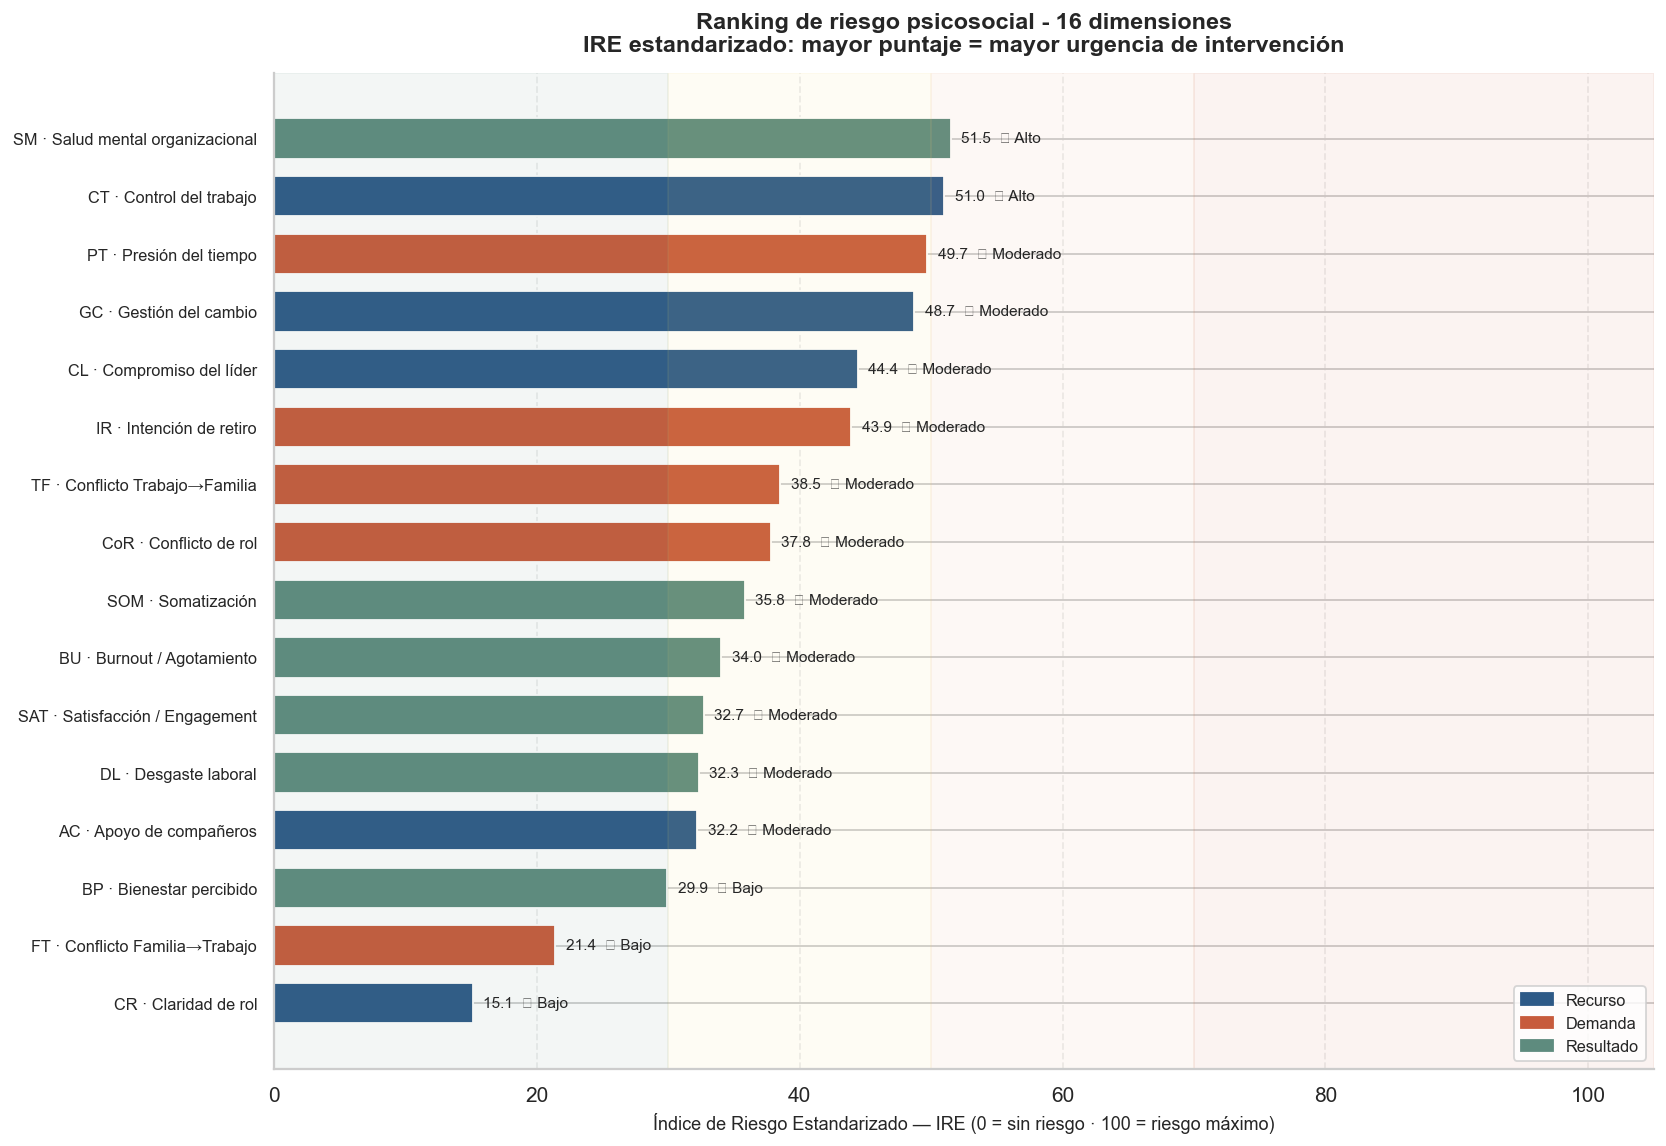

In [31]:
# Ranking de riesgo
fig, ax = plt.subplots(figsize=(13, 9))

labels  = ranking['Dim'] + ' · ' + ranking['Descripción']
ire_val = ranking['IRE (0–100)']
colores = [color_dim(dim) for dim in ranking['Dim']]

bars = ax.barh(labels[::-1], ire_val[::-1], color=colores[::-1],
               edgecolor='white', height=0.7)
for bar, val, cat in zip(bars, ire_val[::-1], ranking['Categoría'][::-1]):
    ax.text(val + 0.8, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}  {cat}', va='center', ha='left', fontsize=8.5)

ax.axvspan(70, 105, alpha=0.07, color='#C75B3C')
ax.axvspan(50, 70,  alpha=0.07, color='#E8A87C')
ax.axvspan(30, 50,  alpha=0.07, color='#F7DC6F')
ax.axvspan(0,  30,  alpha=0.07, color='#5E8B7E')

parche_r  = mpatches.Patch(color=COLOR_RECURSO,   label='Recurso')
parche_d  = mpatches.Patch(color=COLOR_DEMANDA,   label='Demanda')
parche_rs = mpatches.Patch(color=COLOR_RESULTADO, label='Resultado')
ax.legend(handles=[parche_r, parche_d, parche_rs], loc='lower right', fontsize=9)

ax.set_xlabel('Índice de Riesgo Estandarizado — IRE (0 = sin riesgo · 100 = riesgo máximo)',
              fontsize=10)
ax.set_xlim(0, 105)
ax.tick_params(axis='y', labelsize=9)
ax.set_title('Ranking de riesgo psicosocial - 16 dimensiones\n'
             'IRE estandarizado: mayor puntaje = mayor urgencia de intervención',
             fontsize=13, fontweight='bold', pad=12)
ax.grid(axis='x', linestyle='--', alpha=0.35)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

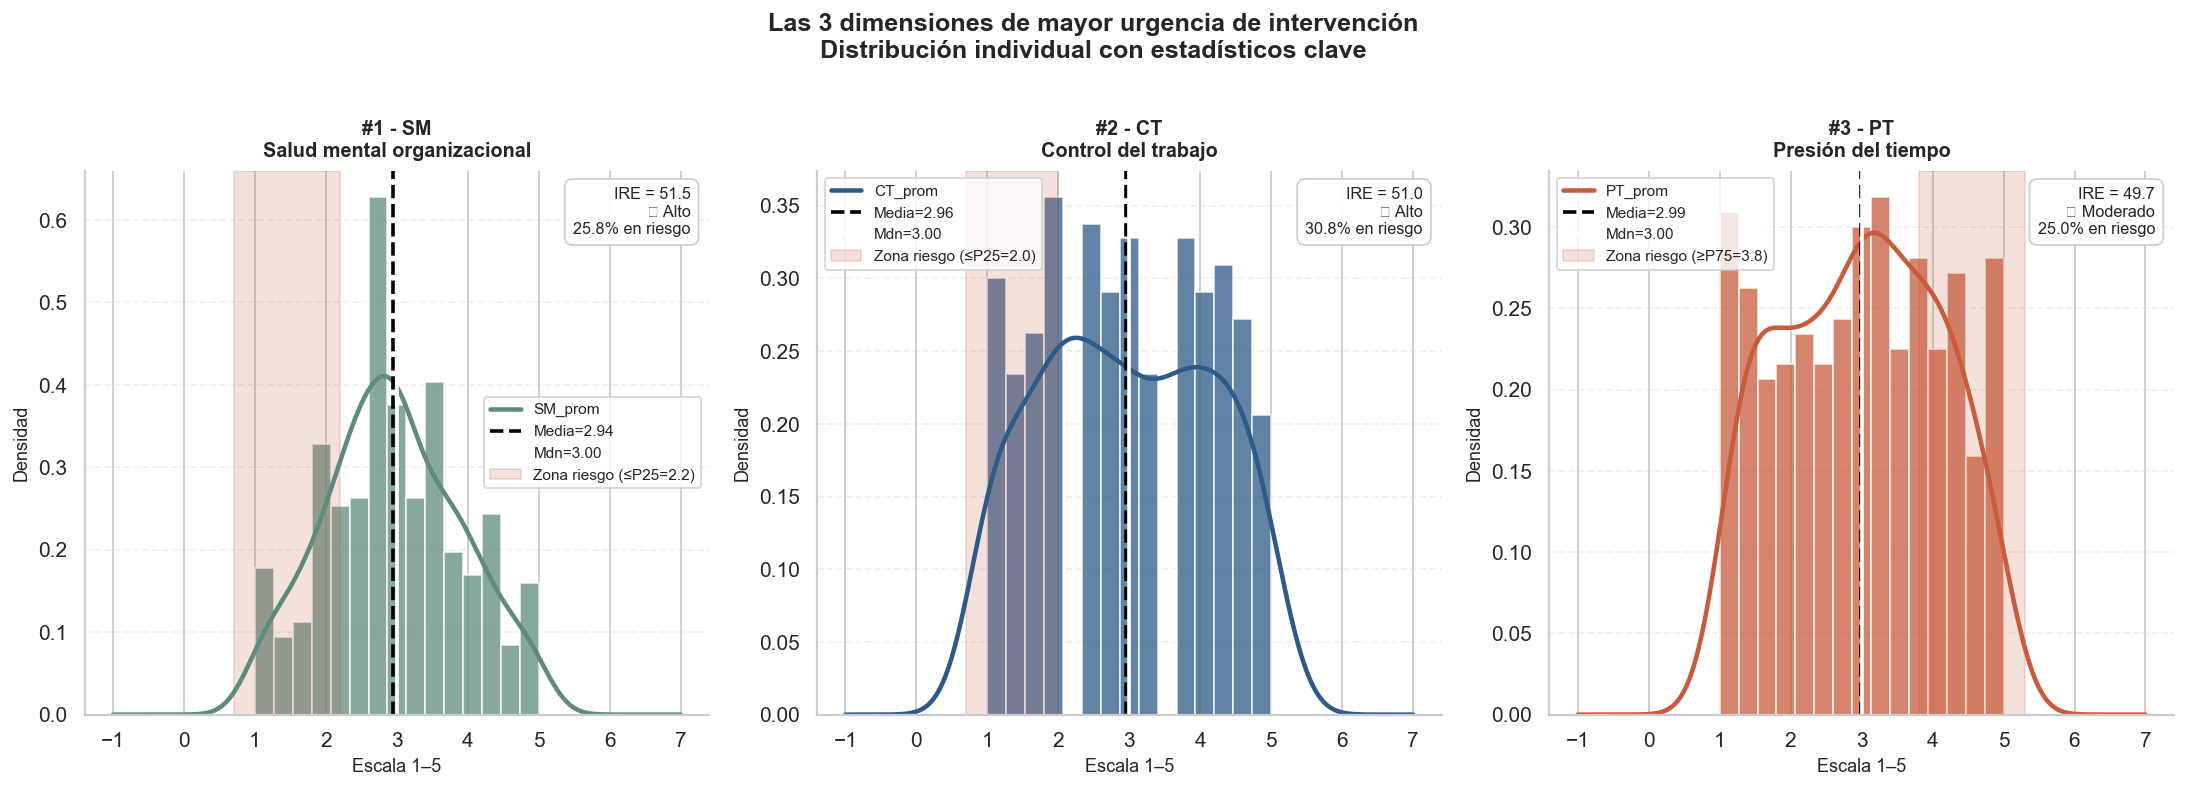


Top 3 dimensiones de mayor urgencia de intervención:
   #1 SM - Salud mental organizacional | IRE=51.5 | 🟠 Alto
   #2 CT - Control del trabajo | IRE=51.0 | 🟠 Alto
   #3 PT - Presión del tiempo | IRE=49.7 | 🟡 Moderado


In [35]:
# Top 3 dimensiones de intervención
top3 = ranking.head(3)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
fig.suptitle('Las 3 dimensiones de mayor urgencia de intervención\n'
             'Distribución individual con estadísticos clave',
             fontsize=14, fontweight='bold', y=1.01)

for i, (ax, (_, row)) in enumerate(zip(axes, top3.iterrows())):
    dim = row['Dim']
    col = dim + '_prom'
    if col not in df.columns or df[col].isnull().all():
        ax.set_visible(False)
        continue

    serie = df[col].dropna()
    color = color_dim(dim)
    tipo, escala, desc = dimensiones_info[dim]
    max_val = escalas_max.get(dim, 7)
    dir_r   = direccion_riesgo[dim]

    ax.hist(serie, bins=15, color=color, edgecolor='white', alpha=0.75, density=True)
    serie.plot.kde(ax=ax, color=color, linewidth=2.5)

    media, mediana = serie.mean(), serie.median()
    p75, p25 = serie.quantile(0.75), serie.quantile(0.25)

    ax.axvline(media,   color='black', lw=2, linestyle='--', label=f'Media={media:.2f}')
    ax.axvline(mediana, color='white', lw=2, linestyle='-',  label=f'Mdn={mediana:.2f}')

    min_plot_val = 0.7
    max_plot_val = 7.3 if max_val == 7 else 5.3
    if dir_r == 'alto':
        ax.axvspan(max(min_plot_val, p75), max_plot_val, alpha=0.18,
                   color='#C75B3C', label=f'Zona riesgo (≥P75={p75:.1f})')
    else:
        ax.axvspan(min_plot_val, min(max_plot_val, p25), alpha=0.18,
                   color='#C75B3C', label=f'Zona riesgo (≤P25={p25:.1f})')

    ax.set_title(f'#{i+1} - {dim}\n{desc}', fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel(f'Escala {escala}', fontsize=10)
    ax.set_ylabel('Densidad', fontsize=10)
    ax.legend(fontsize=8.5)

    texto = f'IRE = {row["IRE (0–100)"]:.1f}\n{row["Categoría"]}\n{row["% en Riesgo"]:.1f}% en riesgo'
    ax.text(0.97, 0.97, texto, transform=ax.transAxes, ha='right', va='top',
            fontsize=9, bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                                  edgecolor='#ccc', alpha=0.95))
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print('\nTop 3 dimensiones de mayor urgencia de intervención:')
for i, (_, row) in enumerate(top3.iterrows(), 1):
    print(f'   #{i} {row["Dim"]} - {row["Descripción"]} | IRE={row["IRE (0–100)"]:.1f} | {row["Categoría"]}')

**Interpretación del ranking** 

Las tres dimensiones de mayor riesgo son **Salud Mental organizacional (SM)**, **Control del trabajo (CT)** y **Presión del tiempo (PT)**, las tres en categoría *Alto* (IRE ≈ 49-52) y con valores muy próximos entre sí.

Es un hallazgo coherente con el modelo Job Demands-Resources: aparece un recurso deteriorado (CT, bajo margen de decisión), una demanda elevada (PT, presión temporal) y un resultado comprometido (SM). Ninguna dimensión alcanza la categoría *Muy alto* (IRE ≥ 70), lo que indica que la organización no está en crisis aguda, pero sí presenta un nivel de riesgo psicosocial generalizado que justifica intervención preventiva. En el extremo opuesto, **Claridad de rol (CR)** es la dimensión más saludable (IRE ≈ 15): los trabajadores saben qué se espera de ellos.

## **Sección 4 - Análisis Bivariado**

### 4.1 Matriz de correlaciones

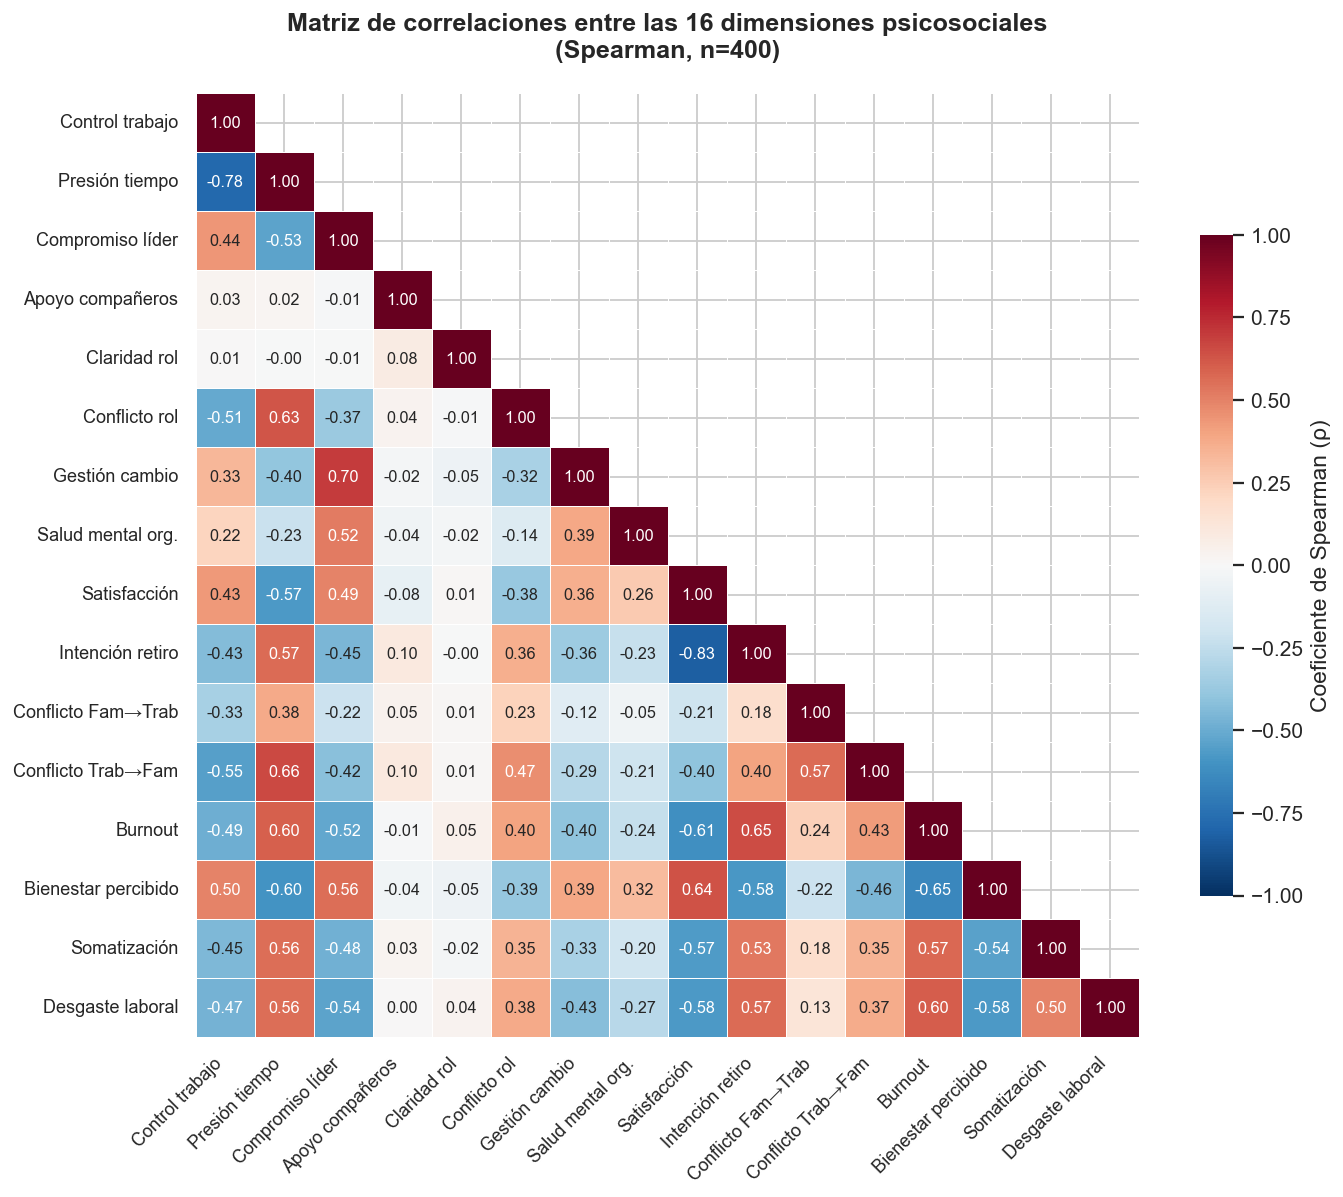

In [36]:
# Matriz de correlaciones (Spearman) de las 16 dimensiones
dimensiones_corr = ['CT_prom', 'PT_prom', 'CL_prom', 'AC_prom', 'CR_prom',
                    'CoR_prom', 'GC_prom', 'SM_prom', 'SAT_prom', 'IR_prom',
                    'FT_prom', 'TF_prom', 'BU_prom', 'BP_prom', 'SOM_prom', 'DL_prom']

etiquetas = ['Control trabajo', 'Presión tiempo', 'Compromiso líder',
             'Apoyo compañeros', 'Claridad rol', 'Conflicto rol',
             'Gestión cambio', 'Salud mental org.', 'Satisfacción',
             'Intención retiro', 'Conflicto Fam→Trab', 'Conflicto Trab→Fam',
             'Burnout', 'Bienestar percibido', 'Somatización', 'Desgaste laboral']

# Spearman: las 16 variables fallan el test de normalidad (Shapiro-Wilk p<0.001)
corr = df[dimensiones_corr].corr(method='spearman')
corr.index = etiquetas
corr.columns = etiquetas

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor='white',
            cbar_kws={'shrink': 0.7, 'label': 'Coeficiente de Spearman (ρ)'},
            annot_kws={'size': 9}, xticklabels=etiquetas, yticklabels=etiquetas, ax=ax)
ax.set_title('Matriz de correlaciones entre las 16 dimensiones psicosociales\n(Spearman, n=400)',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)
plt.subplots_adjust(bottom=0.22, left=0.18)
plt.show()

- **Por qué un heatmap.** Con 16 dimensiones hay 120 pares posibles. Una tabla numérica obliga a leer celda por celda; un heatmap codifica el signo y la magnitud de cada correlación con color y permite identificar patrones de un vistazo. Es el estándar en análisis psicosocial cuando se trabaja con baterías de escalas.

- **Por qué Spearman y no Pearson.** El diagnóstico previo mostró que las 16 dimensiones violan normalidad (Shapiro-Wilk p<0.001 en todas). Spearman trabaja sobre rangos, no asume linealidad ni normalidad, y es robusta a outliers.

- **Por qué máscara triangular.** La matriz es simétrica (corr(A,B) = corr(B,A)). Mostrar solo la mitad inferior elimina ruido visual y duplica el espacio disponible para cada celda.

- **Por qué paleta divergente centrada en cero.** El signo importa tanto como la magnitud. La paleta RdBu_r deja el cero en blanco y distingue dirección con color sin codificar "bueno/malo" (el rojo aquí significa "positiva", no "preocupante").

**Lectura de la matriz.** Se observan dos bloques claros. El primero agrupa las dimensiones de demanda y desgaste (Presión del tiempo, Conflicto de rol, Conflicto Trabajo→Familia, Burnout, Somatización, Desgaste laboral, Intención de retiro), que correlacionan positivamente entre sí con magnitudes moderadas a fuertes. El segundo agrupa los recursos y resultados positivos (Control del trabajo, Compromiso del líder, Gestión del cambio, Salud mental organizacional, Satisfacción, Bienestar percibido), igualmente correlacionados entre sí. Ambos bloques se conectan por correlaciones negativas: a más demanda, menos recurso percibido.

Entre las asociaciones más fuertes destacan **Satisfacción ↔ Intención de retiro (ρ ≈ -0.83)** -la relación más intensa de toda la matriz- y **Control del trabajo ↔ Presión del tiempo (ρ ≈ -0.78)**. Su magnitud tan alta invita a cierta cautela: pueden reflejar parcialmente solapamiento conceptual entre las escalas además de una relación sustantiva real.

Dos dimensiones se comportan como "islas": **Apoyo de compañeros** y **Claridad de rol** presentan correlaciones cercanas a cero con casi todas las demás variables. Esto es un hallazgo, no un error: sugiere que en esta muestra funcionan con relativa independencia del resto del sistema demanda-recurso.

**Cautelas metodológicas.** Las correlaciones se basan en autoreporte de un mismo respondiente en un mismo momento, lo que infla artificialmente la magnitud por varianza de método común. Adicionalmente, correlación no implica causalidad ni descarta variables confundidoras (cultura organizacional, ingreso, antigüedad). Las relaciones son monotónicas pero no necesariamente lineales.

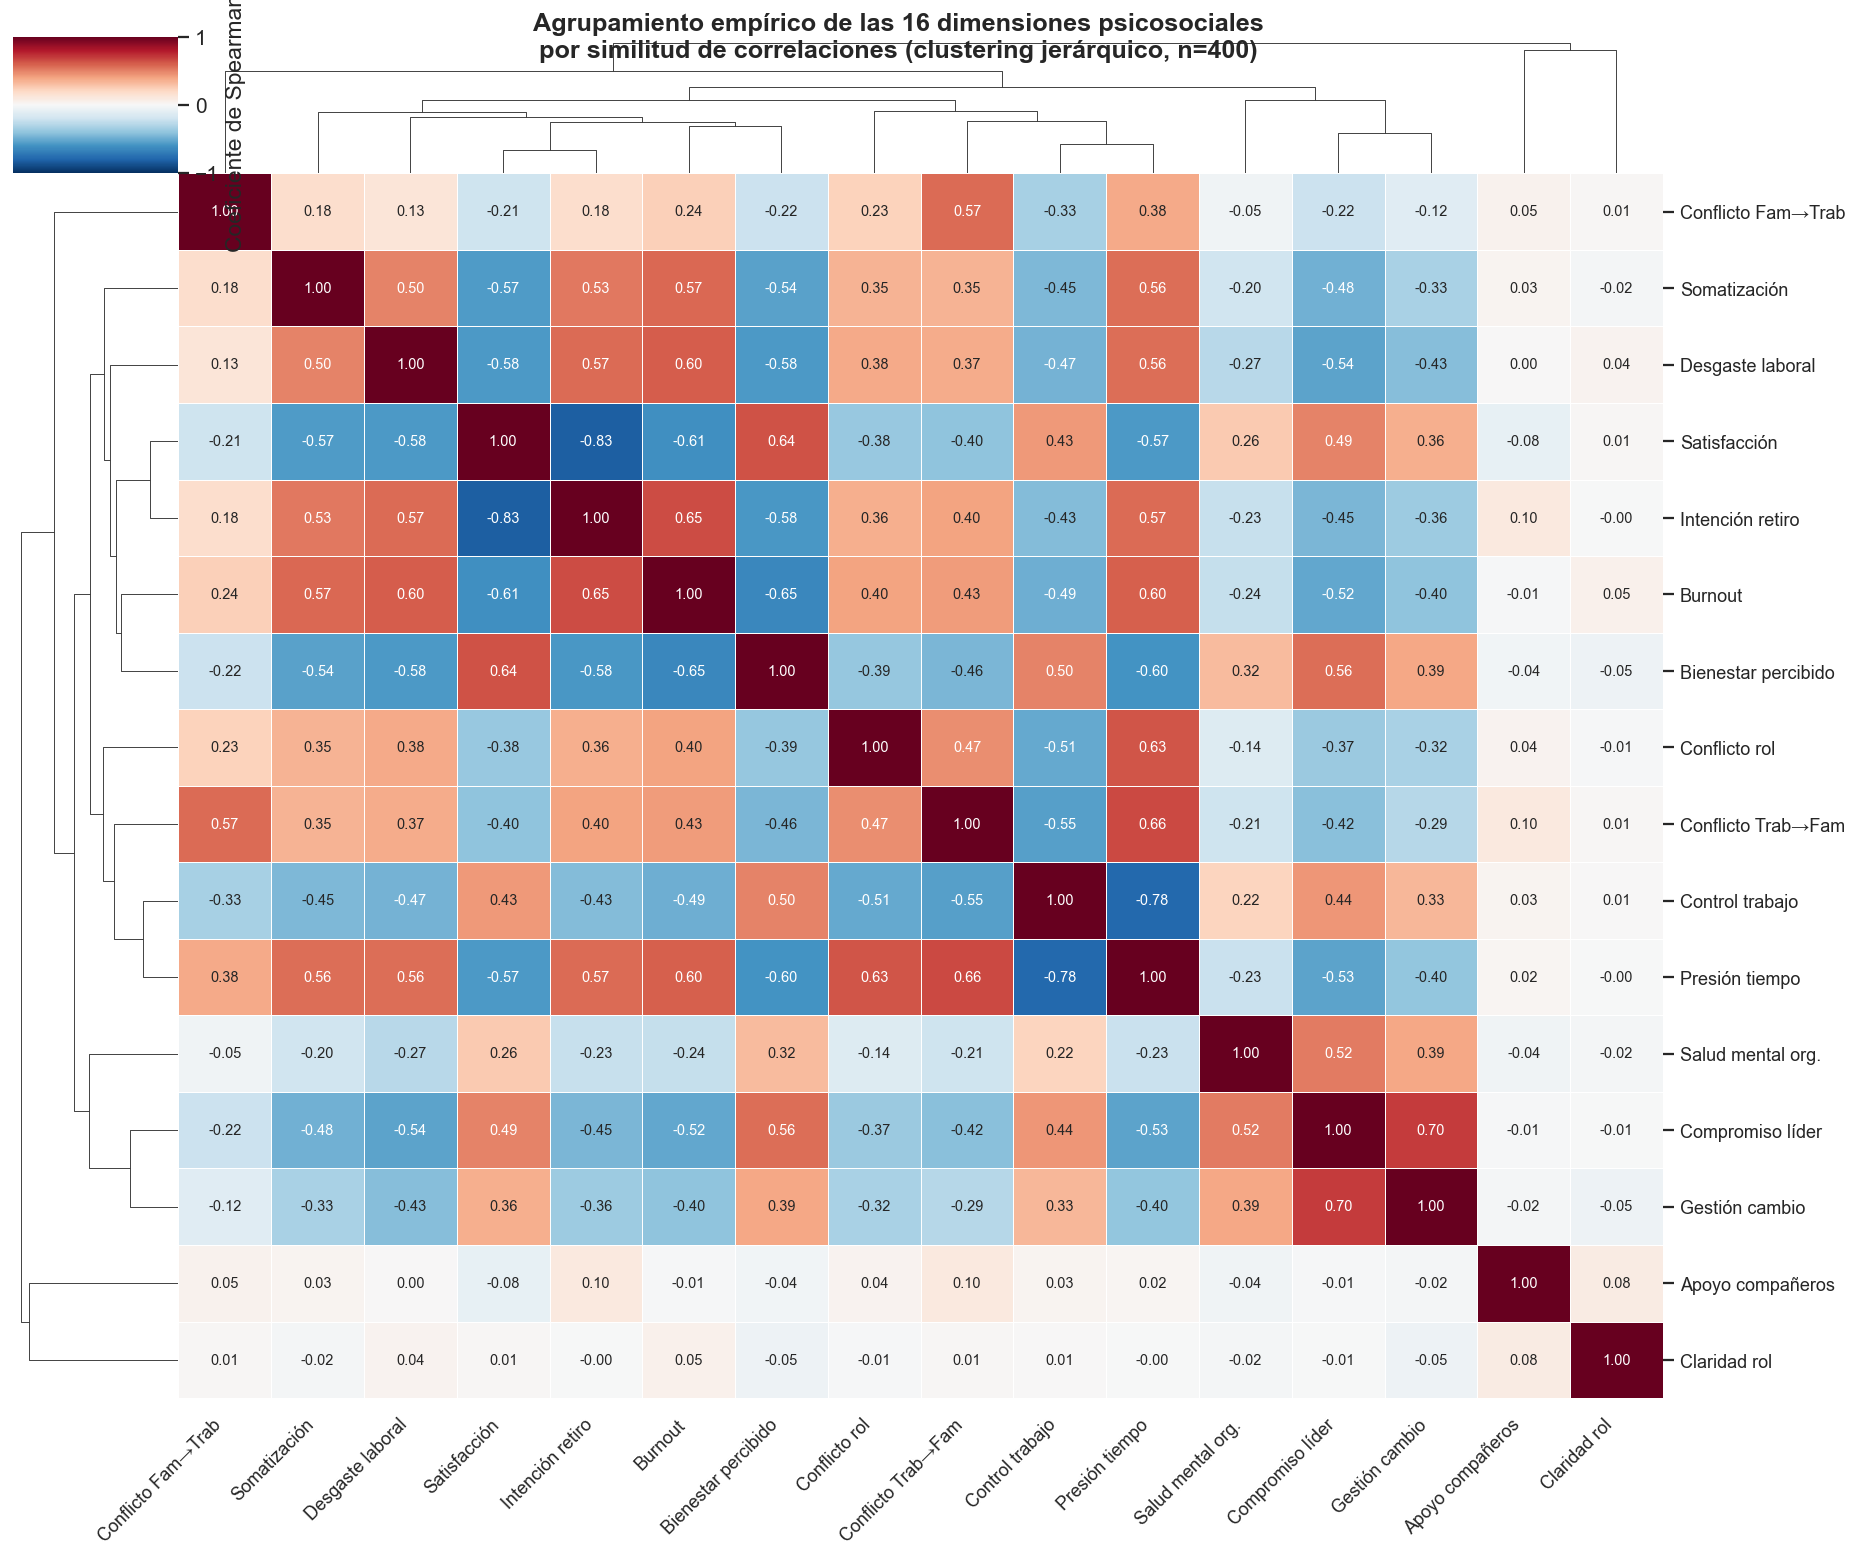

In [37]:
# Agrupamiento empírico de las 16 dimensiones (clustering jerárquico)
corr_cl = df[dimensiones_corr].corr(method='spearman')
corr_cl.index = etiquetas
corr_cl.columns = etiquetas

# Matriz de distancias: 1 - |ρ|  (agrupa por fuerza de correlación, ignora el signo)
dist = 1 - corr_cl.abs()
linkage_matrix = linkage(squareform(dist, checks=False), method='average')

g = sns.clustermap(
    corr_cl, row_linkage=linkage_matrix, col_linkage=linkage_matrix,
    cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f',
    annot_kws={'size': 8}, linewidths=0.5, linecolor='white', figsize=(14, 13),
    cbar_kws={'label': 'Coeficiente de Spearman (ρ)'},
    cbar_pos=(0.02, 0.83, 0.03, 0.12), dendrogram_ratio=0.10,
)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right', fontsize=10)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=10)
g.fig.suptitle('Agrupamiento empírico de las 16 dimensiones psicosociales\n'
               'por similitud de correlaciones (clustering jerárquico, n=400)',
               fontsize=14, fontweight='bold', y=1.00)
g.fig.subplots_adjust(bottom=0.18, right=0.92)
plt.show()

El algoritmo identificó tres agrupamientos distinguibles. El primero -**y más compacto**- reúne las dimensiones de desgaste y demanda (Burnout, Desgaste laboral, Somatización, Intención de retiro, Conflicto de rol, Conflicto Trabajo→Familia, Presión del tiempo). El segundo agrupa los recursos organizacionales y resultados positivos (Compromiso del líder, Gestión del cambio, Salud mental organizacional, Satisfacción, Bienestar percibido, Control del trabajo). Ambos bloques se vinculan entre sí por correlaciones negativas: a mayor recurso percibido, menor desgaste reportado.

Dos dimensiones quedan empíricamente aisladas. **Apoyo de compañeros** y **Claridad de rol** aparecen al final del dendrograma como ramas independientes, con correlaciones cercanas a cero frente a todas las demás. Esto sugiere que, en esta muestra, ambas funcionan de manera relativamente autónoma respecto al sistema demanda-recurso. Podría reflejar techo psicométrico (Claridad de rol tiene media de 4.39 sobre 5, con poca varianza para correlacionar) o genuina independencia conceptual.

**Conflicto Familia→Trabajo se comporta distinto al Conflicto Trabajo→Familia.** Aunque ambos miden interferencia entre dominios, FT queda separado del cluster de desgaste mientras TF se integra plenamente a él. Esto es consistente con la literatura previa: el conflicto en dirección trabajo→familia está más asociado con burnout que el inverso.

**Cautela.** El clustering jerárquico es exploratorio. La estructura observada es plausible y consistente con el modelo JD-R, pero confirmarla como solución factorial requeriría un análisis factorial confirmatorio (AFC), fuera del alcance de este EDA.

### 4.2 Pares clave

Se analizan en detalle **seis pares de dimensiones** seleccionados por su relevancia teórica y por responder directamente a las preguntas orientadoras del proyecto. Para cada par se reporta el coeficiente de **Spearman** como prueba principal (las variables fallan el test de normalidad), **Pearson** como referencia de linealidad, y un **intervalo de confianza al 95 % por bootstrap** (1.000
remuestreos, semilla fija) que cuantifica la incertidumbre sobre la magnitud real.

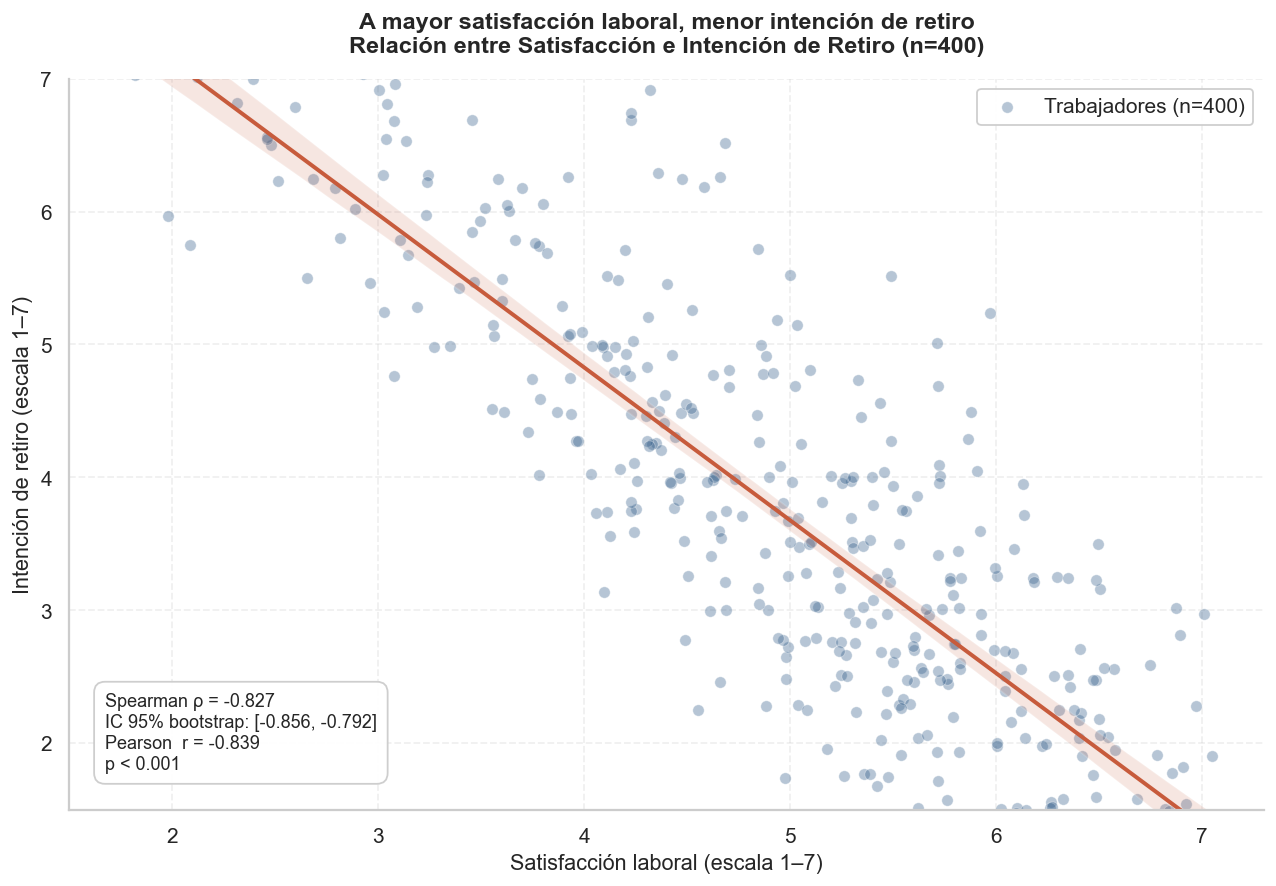


Magnitud del efecto: |ρ| = 0.827 → fuerte


In [38]:
# PAR 1 - Satisfacción laboral vs Intención de retiro
x, y = df['SAT_prom'], df['IR_prom']

rho_s, p_s = stats.spearmanr(x, y)
rho_p, p_p = stats.pearsonr(x, y)

rng = np.random.default_rng(42)
n = len(x)
boot_rhos = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    r, _ = stats.spearmanr(x.iloc[idx], y.iloc[idx])
    boot_rhos.append(r)
ic_low, ic_high = np.percentile(boot_rhos, [2.5, 97.5])

jitter_x = x + rng.normal(0, 0.05, size=n)
jitter_y = y + rng.normal(0, 0.05, size=n)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(jitter_x, jitter_y, alpha=0.35, s=40, color='#2E5A87',
           edgecolor='white', linewidth=0.5, label=f'Trabajadores (n={n})')
sns.regplot(x=x, y=y, ax=ax, scatter=False,
            line_kws={'color': '#C75B3C', 'linewidth': 2.2}, ci=95, truncate=False)

texto_stats = (f'Spearman ρ = {rho_s:.3f}\n'
               f'IC 95% bootstrap: [{ic_low:.3f}, {ic_high:.3f}]\n'
               f'Pearson  r = {rho_p:.3f}\n'
               f'p < 0.001')
ax.text(0.03, 0.05, texto_stats, transform=ax.transAxes, fontsize=10,
        verticalalignment='bottom',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_xlabel('Satisfacción laboral (escala 1–7)', fontsize=12)
ax.set_ylabel('Intención de retiro (escala 1–7)', fontsize=12)
ax.set_title('A mayor satisfacción laboral, menor intención de retiro\n'
             f'Relación entre Satisfacción e Intención de Retiro (n={n})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc='upper right', frameon=True, framealpha=0.95)
ax.set_xlim(1.5, 7.3)
ax.set_ylim(1.5, 7.0)
plt.tight_layout()
plt.show()

print(f'\nMagnitud del efecto: |ρ| = {abs(rho_s):.3f} → '
      f'{"fuerte" if abs(rho_s) >= 0.5 else "moderado" if abs(rho_s) >= 0.3 else "trivial"}')

La correlación negativa es **muy fuerte** (ρ = -0.83, |ρ| ≥ 0.50). A mayor satisfacción, menor intención de retiro. La similitud entre Spearman y Pearson confirma que la relación es prácticamente lineal.

**Implicación:** la satisfacción actúa como indicador anticipado de rotación. Intervenciones que la mejoren deberían tener retorno medible en retención de talento.

**Cautela:** correlación no implica causalidad (posibles terceros factores: liderazgo, condiciones contractuales) y la magnitud tan alta sugiere cierto solapamiento conceptual entre las escalas.

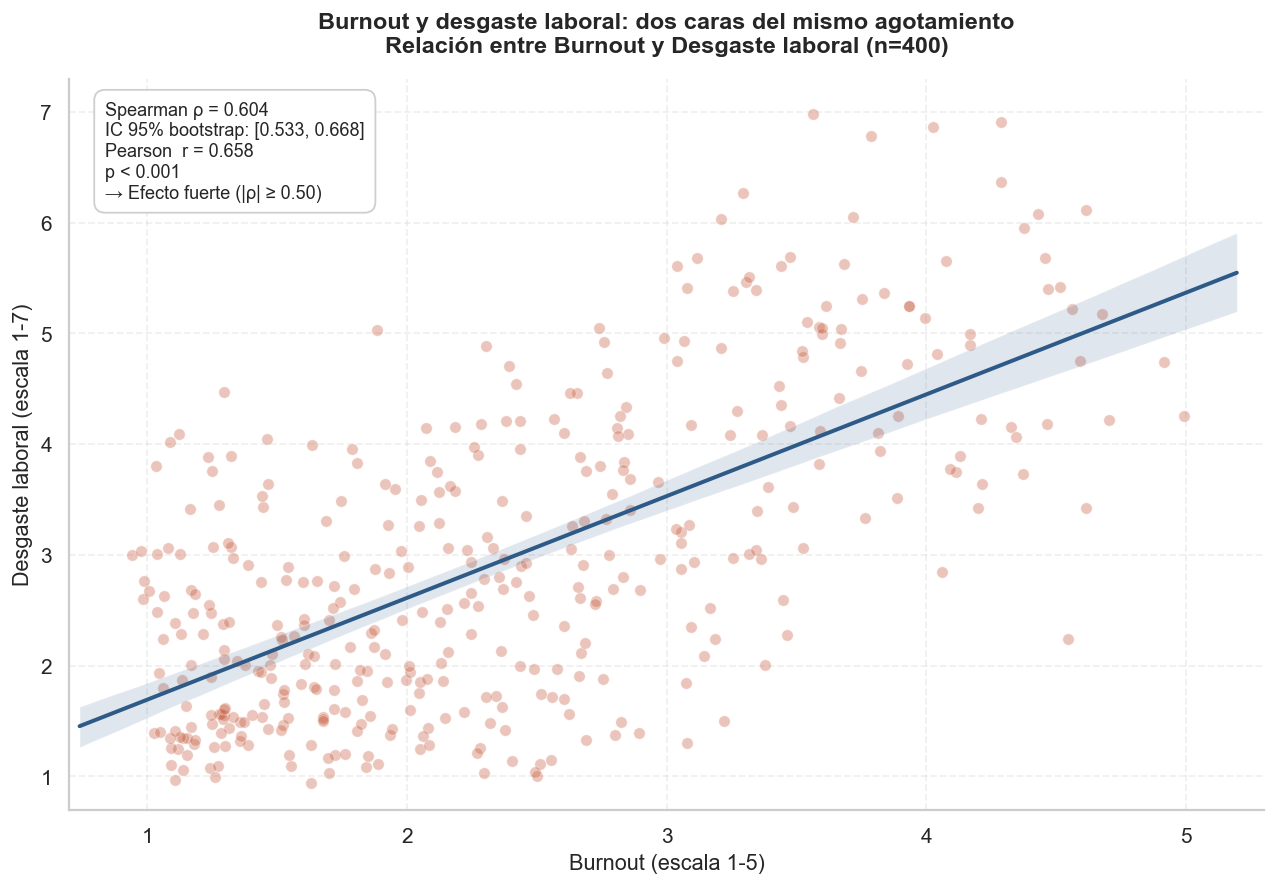

In [39]:
# PAR 2 - Burnout vs Desgaste laboral
x, y = df['BU_prom'], df['DL_prom']

rho_s, p_s = stats.spearmanr(x, y)
rho_p, p_p = stats.pearsonr(x, y)

rng = np.random.default_rng(42)
n = len(x)
boot_rhos = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    r, _ = stats.spearmanr(x.iloc[idx], y.iloc[idx])
    boot_rhos.append(r)
ic_low, ic_high = np.percentile(boot_rhos, [2.5, 97.5])

interpretacion = ('Efecto fuerte (|ρ| ≥ 0.50)' if abs(rho_s) >= 0.5
                  else 'Efecto moderado (0.30 ≤ |ρ| < 0.50)' if abs(rho_s) >= 0.3
                  else 'Efecto pequeño/trivial')

jitter_x = x + rng.normal(0, 0.05, size=n)
jitter_y = y + rng.normal(0, 0.05, size=n)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(jitter_x, jitter_y, alpha=0.35, s=40, color='#C75B3C',
           edgecolor='white', linewidth=0.5)
sns.regplot(x=x, y=y, ax=ax, scatter=False,
            line_kws={'color': '#2E5A87', 'linewidth': 2.2}, ci=95, truncate=False)

texto_stats = (f'Spearman ρ = {rho_s:.3f}\n'
               f'IC 95% bootstrap: [{ic_low:.3f}, {ic_high:.3f}]\n'
               f'Pearson  r = {rho_p:.3f}\n'
               f'p < 0.001\n→ {interpretacion}')
ax.text(0.03, 0.97, texto_stats, transform=ax.transAxes, fontsize=10,
        verticalalignment='top',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_xlabel('Burnout (escala 1-5)', fontsize=12)
ax.set_ylabel('Desgaste laboral (escala 1-7)', fontsize=12)
ax.set_title('Burnout y desgaste laboral: dos caras del mismo agotamiento\n'
             f'Relación entre Burnout y Desgaste laboral (n={n})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0.7, 5.3)
ax.set_ylim(0.7, 7.3)
plt.tight_layout()
plt.show()

Correlación positiva **fuerte** (ρ = +0.60). Ambas dimensiones comparten una proporción sustancial de varianza, lo que sugiere que capturan manifestaciones del mismo proceso de agotamiento.

**Implicación:** Las intervenciones que reduzcan burnout probablemente alivian también el desgaste laboral.

**Cautela:** Un ρ de 0.60 deja ~64 % de varianza no compartida, y el autoreporte simultáneo infla parte de la correlación.

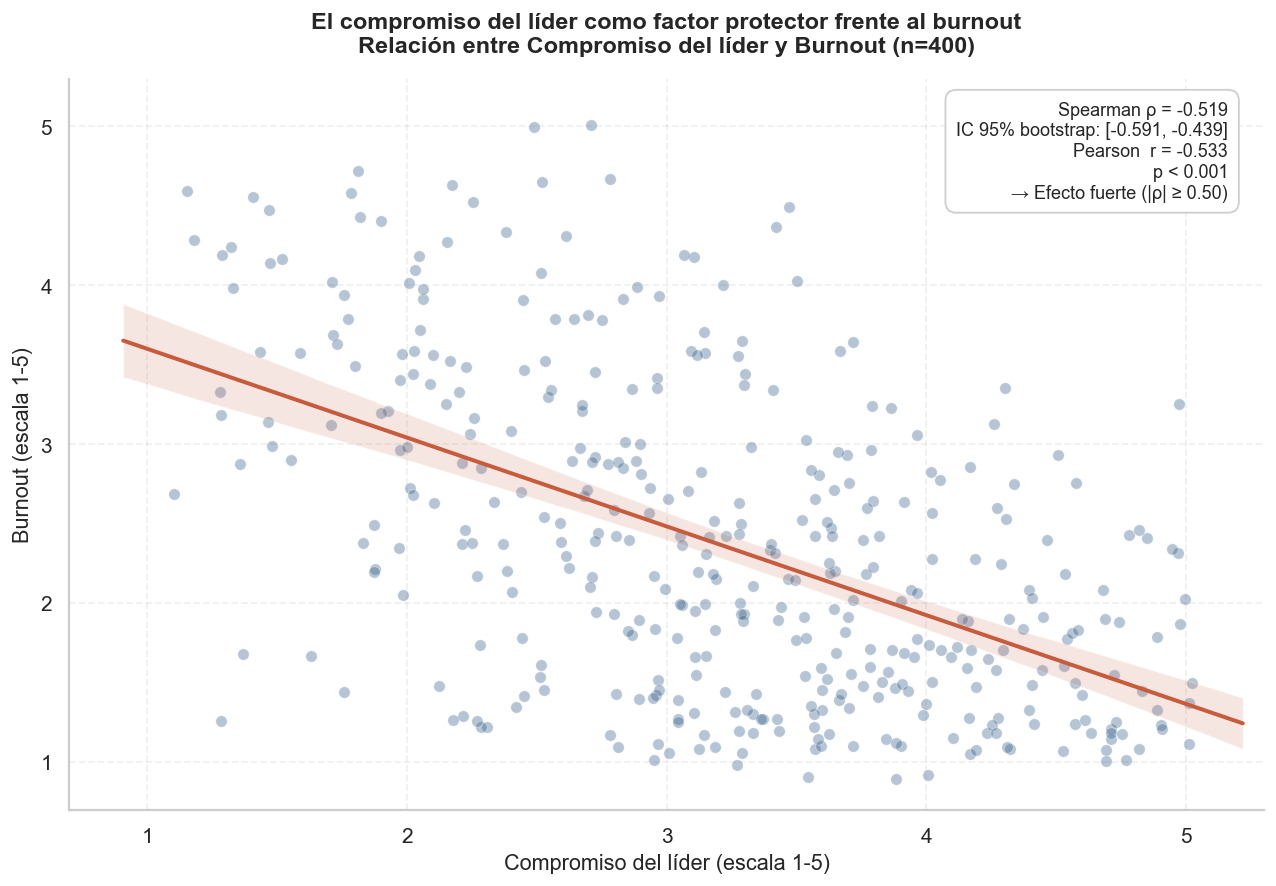

In [40]:
# PAR 3- Compromiso del líder vs Burnout
x, y = df['CL_prom'], df['BU_prom']

rho_s, p_s = stats.spearmanr(x, y)
rho_p, p_p = stats.pearsonr(x, y)

rng = np.random.default_rng(42)
n = len(x)
boot_rhos = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    r, _ = stats.spearmanr(x.iloc[idx], y.iloc[idx])
    boot_rhos.append(r)
ic_low, ic_high = np.percentile(boot_rhos, [2.5, 97.5])

interpretacion = ('Efecto fuerte (|ρ| ≥ 0.50)' if abs(rho_s) >= 0.5
                  else 'Efecto moderado (0.30 ≤ |ρ| < 0.50)' if abs(rho_s) >= 0.3
                  else 'Efecto pequeño/trivial')

jitter_x = x + rng.normal(0, 0.05, size=n)
jitter_y = y + rng.normal(0, 0.05, size=n)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(jitter_x, jitter_y, alpha=0.35, s=40, color='#2E5A87',
           edgecolor='white', linewidth=0.5)
sns.regplot(x=x, y=y, ax=ax, scatter=False,
            line_kws={'color': '#C75B3C', 'linewidth': 2.2}, ci=95, truncate=False)

texto_stats = (f'Spearman ρ = {rho_s:.3f}\n'
               f'IC 95% bootstrap: [{ic_low:.3f}, {ic_high:.3f}]\n'
               f'Pearson  r = {rho_p:.3f}\n'
               f'p < 0.001\n→ {interpretacion}')
ax.text(0.97, 0.97, texto_stats, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_xlabel('Compromiso del líder (escala 1-5)', fontsize=12)
ax.set_ylabel('Burnout (escala 1-5)', fontsize=12)
ax.set_title('El compromiso del líder como factor protector frente al burnout\n'
             f'Relación entre Compromiso del líder y Burnout (n={n})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0.7, 5.3)
ax.set_ylim(0.7, 5.3)
plt.tight_layout()
plt.show()

Correlación negativa **fuerte** (ρ = -0.52). A mayor compromiso del líder percibido, menor burnout reportado.

**Implicación:** El liderazgo funciona como recurso protector. Intervenciones de desarrollo de liderazgo (formación, evaluación 360°, coaching) tienen retorno medible en salud mental del equipo.

**Cautela:** La dispersión visible muestra que el liderazgo es relevante pero no suficiente; ambas variables comparten fuente de medición.

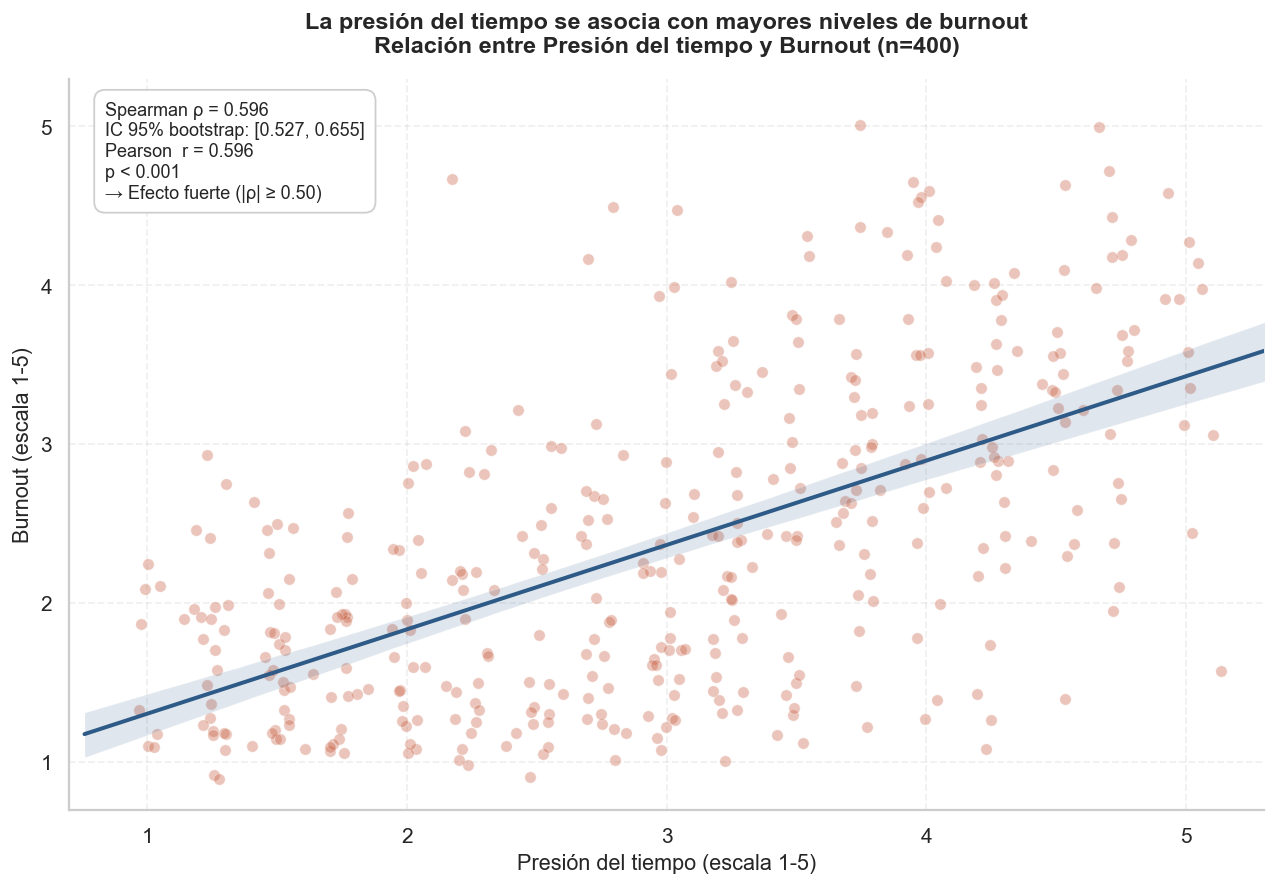

In [41]:
# PAR 4 - Presión del tiempo vs Burnout
x, y = df['PT_prom'], df['BU_prom']

rho_s, p_s = stats.spearmanr(x, y)
rho_p, p_p = stats.pearsonr(x, y)

rng = np.random.default_rng(42)
n = len(x)
boot_rhos = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    r, _ = stats.spearmanr(x.iloc[idx], y.iloc[idx])
    boot_rhos.append(r)
ic_low, ic_high = np.percentile(boot_rhos, [2.5, 97.5])

interpretacion = ('Efecto fuerte (|ρ| ≥ 0.50)' if abs(rho_s) >= 0.5
                  else 'Efecto moderado (0.30 ≤ |ρ| < 0.50)' if abs(rho_s) >= 0.3
                  else 'Efecto pequeño/trivial')

jitter_x = x + rng.normal(0, 0.05, size=n)
jitter_y = y + rng.normal(0, 0.05, size=n)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(jitter_x, jitter_y, alpha=0.35, s=40, color='#C75B3C',
           edgecolor='white', linewidth=0.5)
sns.regplot(x=x, y=y, ax=ax, scatter=False,
            line_kws={'color': '#2E5A87', 'linewidth': 2.2}, ci=95, truncate=False)

texto_stats = (f'Spearman ρ = {rho_s:.3f}\n'
               f'IC 95% bootstrap: [{ic_low:.3f}, {ic_high:.3f}]\n'
               f'Pearson  r = {rho_p:.3f}\n'
               f'p < 0.001\n→ {interpretacion}')
ax.text(0.03, 0.97, texto_stats, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='left',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_xlabel('Presión del tiempo (escala 1-5)', fontsize=12)
ax.set_ylabel('Burnout (escala 1-5)', fontsize=12)
ax.set_title('La presión del tiempo se asocia con mayores niveles de burnout\n'
             f'Relación entre Presión del tiempo y Burnout (n={n})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0.7, 5.3)
ax.set_ylim(0.7, 5.3)
plt.tight_layout()
plt.show()

Correlación positiva **fuerte** (ρ = +0.60). Pearson y Spearman son idénticos hasta el tercer decimal, lo que indica una relación estrictamente lineal: el burnout aumenta de forma proporcional a la presión temporal.

**Implicación:** Rediseñar cargas de trabajo y plazos es una intervención accionable con efecto medible sobre el agotamiento.

**Cautela:** Podría existir un tercer factor común (déficit de personal, cultura organizacional); el autoreporte infla parte de la correlación.

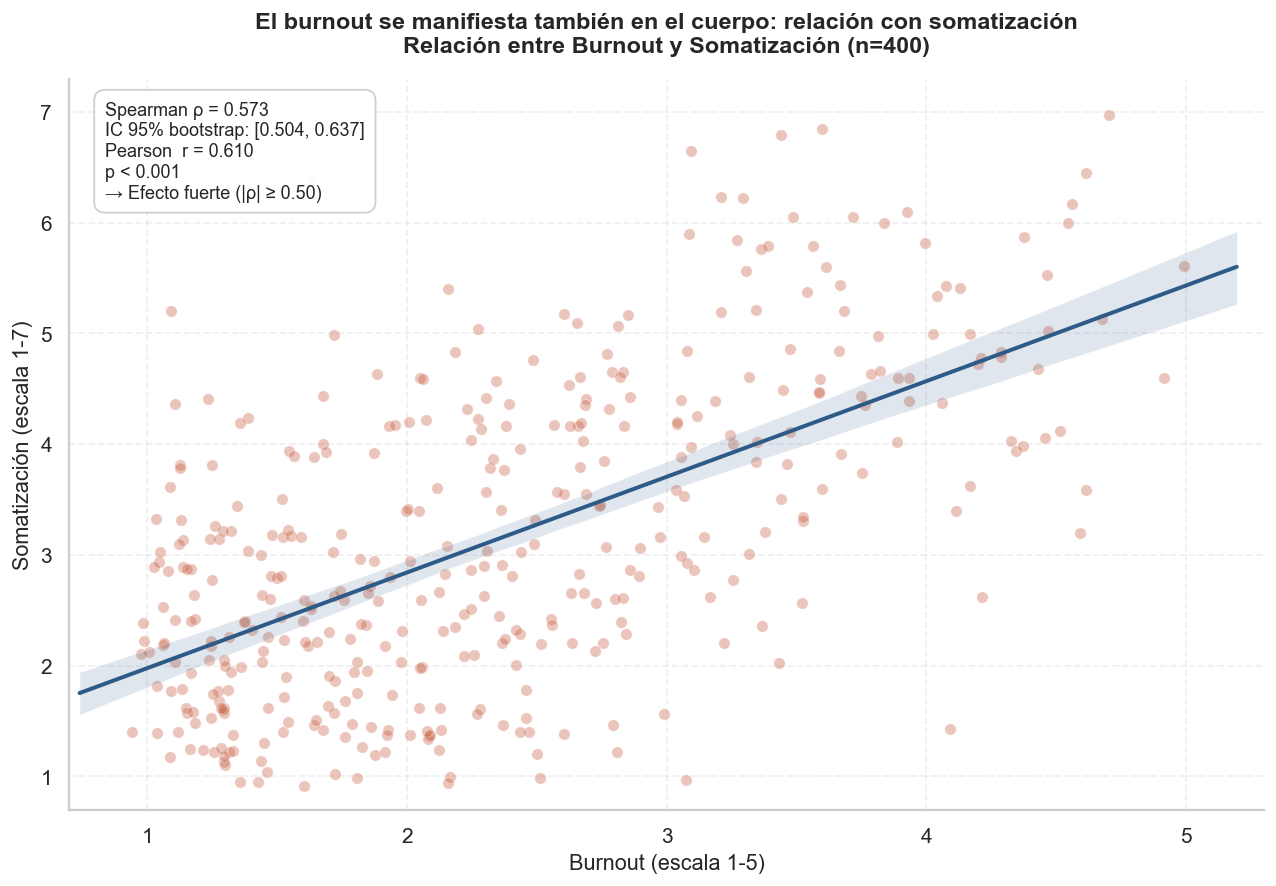

In [42]:
# PAR 5 - Burnout vs Somatización
x, y = df['BU_prom'], df['SOM_prom']

rho_s, p_s = stats.spearmanr(x, y)
rho_p, p_p = stats.pearsonr(x, y)

rng = np.random.default_rng(42)
n = len(x)
boot_rhos = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    r, _ = stats.spearmanr(x.iloc[idx], y.iloc[idx])
    boot_rhos.append(r)
ic_low, ic_high = np.percentile(boot_rhos, [2.5, 97.5])

interpretacion = ('Efecto fuerte (|ρ| ≥ 0.50)' if abs(rho_s) >= 0.5
                  else 'Efecto moderado (0.30 ≤ |ρ| < 0.50)' if abs(rho_s) >= 0.3
                  else 'Efecto pequeño/trivial')

jitter_x = x + rng.normal(0, 0.05, size=n)
jitter_y = y + rng.normal(0, 0.05, size=n)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(jitter_x, jitter_y, alpha=0.35, s=40, color='#C75B3C',
           edgecolor='white', linewidth=0.5)
sns.regplot(x=x, y=y, ax=ax, scatter=False,
            line_kws={'color': '#2E5A87', 'linewidth': 2.2}, ci=95, truncate=False)

texto_stats = (f'Spearman ρ = {rho_s:.3f}\n'
               f'IC 95% bootstrap: [{ic_low:.3f}, {ic_high:.3f}]\n'
               f'Pearson  r = {rho_p:.3f}\n'
               f'p < 0.001\n→ {interpretacion}')
ax.text(0.03, 0.97, texto_stats, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='left',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_xlabel('Burnout (escala 1-5)', fontsize=12)
ax.set_ylabel('Somatización (escala 1-7)', fontsize=12)
ax.set_title('El burnout se manifiesta también en el cuerpo: relación con somatización\n'
             f'Relación entre Burnout y Somatización (n={n})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0.7, 5.3)
ax.set_ylim(0.7, 7.3)
plt.tight_layout()
plt.show()

Correlación positiva **fuerte** (ρ = +0.57). El agotamiento psicológico se expresa también en síntomas físicos, lo que convierte la prevención del burnout en una inversión con retorno tangible en ausentismo y costos de salud.

**Cautela:** La somatización tiene determinantes extralaborales (genética, hábitos, edad), lo que explica la mayor dispersión respecto a pares anteriores.

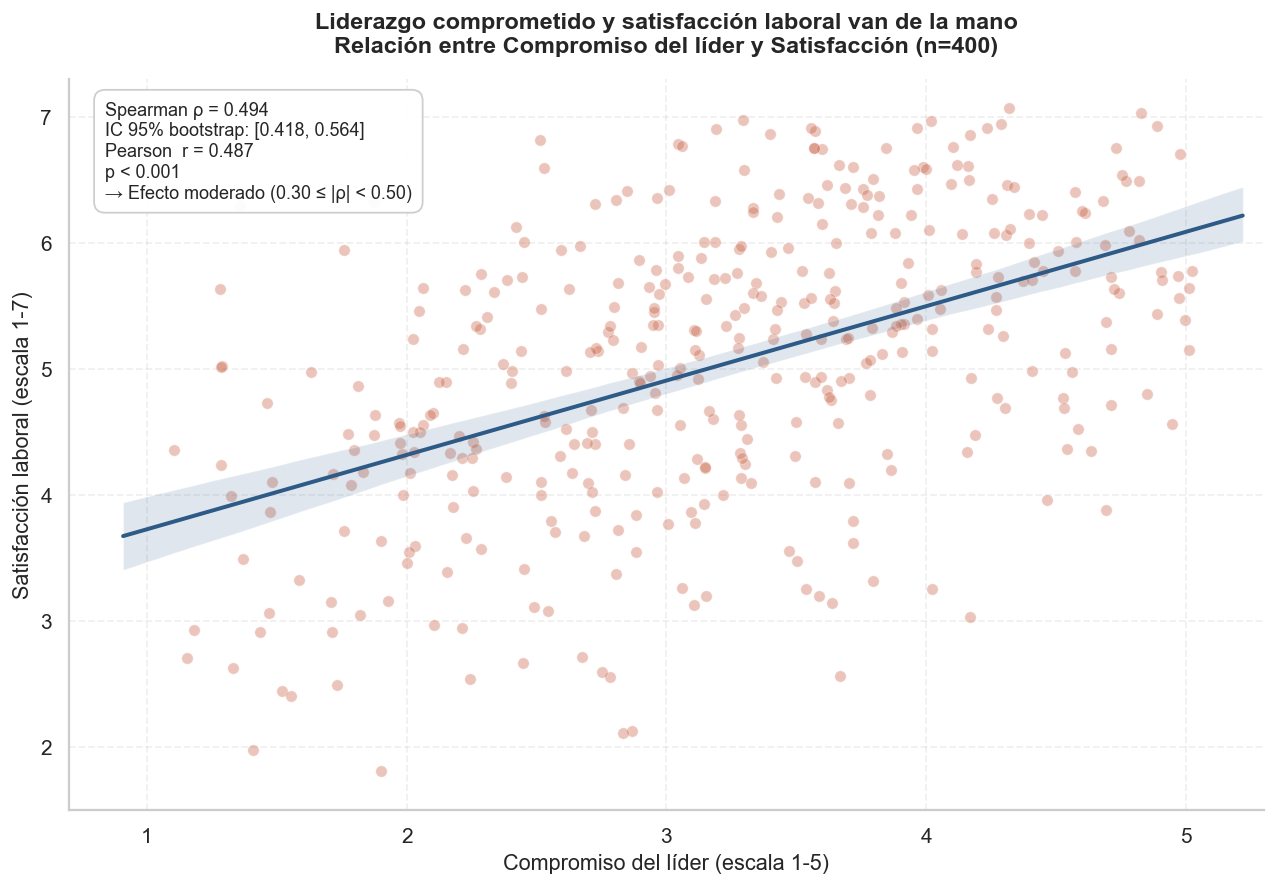

In [43]:
# PAR 6 - Compromiso del líder vs Satisfacción laboral
x, y = df['CL_prom'], df['SAT_prom']

rho_s, p_s = stats.spearmanr(x, y)
rho_p, p_p = stats.pearsonr(x, y)

rng = np.random.default_rng(42)
n = len(x)
boot_rhos = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    r, _ = stats.spearmanr(x.iloc[idx], y.iloc[idx])
    boot_rhos.append(r)
ic_low, ic_high = np.percentile(boot_rhos, [2.5, 97.5])

interpretacion = ('Efecto fuerte (|ρ| ≥ 0.50)' if abs(rho_s) >= 0.5
                  else 'Efecto moderado (0.30 ≤ |ρ| < 0.50)' if abs(rho_s) >= 0.3
                  else 'Efecto pequeño/trivial')

jitter_x = x + rng.normal(0, 0.05, size=n)
jitter_y = y + rng.normal(0, 0.05, size=n)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(jitter_x, jitter_y, alpha=0.35, s=40, color='#C75B3C',
           edgecolor='white', linewidth=0.5)
sns.regplot(x=x, y=y, ax=ax, scatter=False,
            line_kws={'color': '#2E5A87', 'linewidth': 2.2}, ci=95, truncate=False)

texto_stats = (f'Spearman ρ = {rho_s:.3f}\n'
               f'IC 95% bootstrap: [{ic_low:.3f}, {ic_high:.3f}]\n'
               f'Pearson  r = {rho_p:.3f}\n'
               f'p < 0.001\n→ {interpretacion}')
ax.text(0.03, 0.97, texto_stats, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='left',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_xlabel('Compromiso del líder (escala 1-5)', fontsize=12)
ax.set_ylabel('Satisfacción laboral (escala 1-7)', fontsize=12)
ax.set_title('Liderazgo comprometido y satisfacción laboral van de la mano\n'
             f'Relación entre Compromiso del líder y Satisfacción (n={n})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0.7, 5.3)
ax.set_ylim(1.5, 7.3)
plt.tight_layout()
plt.show()

Correlación positiva **moderada** (ρ = +0.49). El liderazgo es un factor relevante pero no el único determinante de la satisfacción: la varianza no explicada (~75 %) deja espacio a otros antecedentes como remuneración, contenido del rol o reconocimiento.

**Implicación:** Invertir en desarrollo de liderazgo es necesario pero insuficiente; debe acompañarse de una estrategia integral de gestión humana.

### 4.3 Comparaciones por grupo

Se comparan indicadores de bienestar entre grupos de trabajadores definidos por variables sociodemográficas. Para grupos de dos categorías se usa **Mann-Whitney U** y para tres categorías **Kruskal-Wallis** con post-hoc de **Dunn** (correcciones no paramétricas, justificadas porque las variables fallan el test de normalidad).

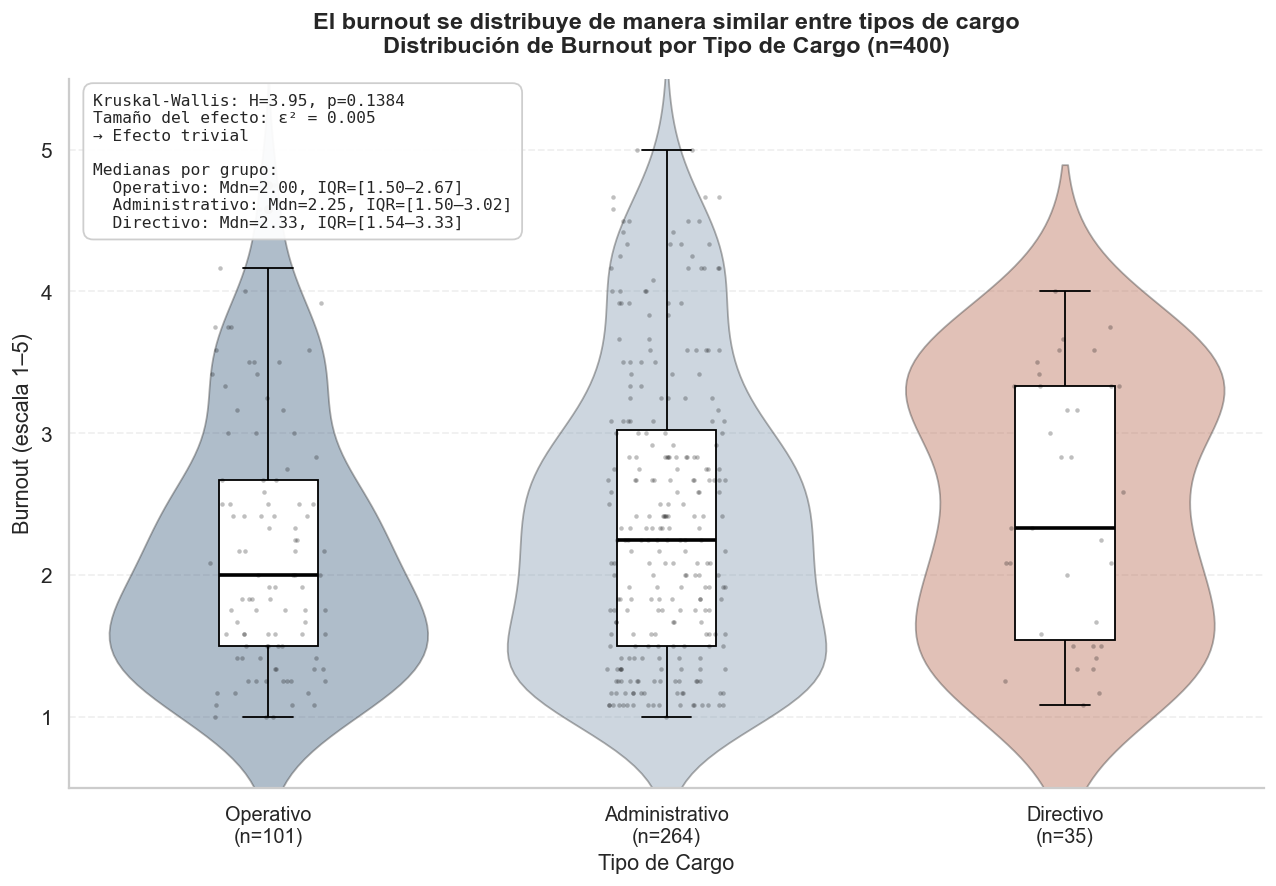


Post-hoc de Dunn (p-values ajustados por Bonferroni)
                Administrativo  Directivo  Operativo
Administrativo          1.0000     1.0000     0.2707
Directivo               1.0000     1.0000     0.2845
Operativo               0.2707     0.2845     1.0000


In [44]:
# COMPARACIÓN 1 · Burnout por Tipo de Cargo
grupo, medida = 'Tipo_Cargo', 'BU_prom'

orden = df.groupby(grupo)[medida].median().sort_values().index.tolist()
n_grupos = df.groupby(grupo).size()
etiquetas_x = [f'{g}\n(n={n_grupos[g]})' for g in orden]

# Kruskal-Wallis (no paramétrico, 3 grupos)
grupos_datos = [df[df[grupo] == g][medida].values for g in orden]
H, p_kw = stats.kruskal(*grupos_datos)

# Tamaño del efecto épsilon²
n_total, k = len(df), len(orden)
epsilon2 = (H - k + 1) / (n_total - k)

# Post-hoc de Dunn con corrección de Bonferroni
dunn = sp.posthoc_dunn(df, val_col=medida, group_col=grupo, p_adjust='bonferroni')

fig, ax = plt.subplots(figsize=(10, 7))
paleta = ['#2E5A87', '#7A9BB8', '#C75B3C']
sns.violinplot(data=df, x=grupo, y=medida, order=orden, palette=paleta,
               inner=None, linewidth=1, alpha=0.4, ax=ax)
sns.boxplot(data=df, x=grupo, y=medida, order=orden, width=0.25,
            boxprops={'facecolor': 'white', 'edgecolor': 'black'},
            medianprops={'color': 'black', 'linewidth': 2},
            whiskerprops={'color': 'black'}, capprops={'color': 'black'},
            flierprops={'marker': 'o', 'markersize': 4,
                        'markerfacecolor': '#666', 'markeredgecolor': '#666'}, ax=ax)
sns.stripplot(data=df, x=grupo, y=medida, order=orden, color='black',
              alpha=0.25, size=2.5, jitter=0.15, ax=ax)

ax.set_xticklabels(etiquetas_x, fontsize=11)
ax.set_xlabel('Tipo de Cargo', fontsize=12)
ax.set_ylabel('Burnout (escala 1–5)', fontsize=12)

medianas = df.groupby(grupo)[medida].median()
q1 = df.groupby(grupo)[medida].quantile(0.25)
q3 = df.groupby(grupo)[medida].quantile(0.75)
linea_medianas = '\n'.join([f'  {g}: Mdn={medianas[g]:.2f}, IQR=[{q1[g]:.2f}–{q3[g]:.2f}]'
                            for g in orden])

interp_efecto = ('Efecto grande' if epsilon2 >= 0.16 else 'Efecto moderado'
                 if epsilon2 >= 0.04 else 'Efecto pequeño' if epsilon2 >= 0.01
                 else 'Efecto trivial')

texto_stats = (f'Kruskal-Wallis: H={H:.2f}, p={p_kw:.4f}\n'
               f'Tamaño del efecto: ε² = {epsilon2:.3f}\n→ {interp_efecto}\n\n'
               f'Medianas por grupo:\n{linea_medianas}')
ax.text(0.02, 0.98, texto_stats, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_title('El burnout se distribuye de manera similar entre tipos de cargo\n'
             f'Distribución de Burnout por Tipo de Cargo (n={n_total})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0.5, 5.5)
plt.tight_layout()
plt.show()

print('\nPost-hoc de Dunn (p-values ajustados por Bonferroni)')
print(dunn.round(4))

**No hay diferencias significativas entre tipos de cargo** (H = 3.95, p = 0.138; ε² = 0.005, efecto trivial). Las medianas son muy cercanas: Operativo 2.00, Administrativo 2.25, Directivo 2.33.

**Implicación:** Las intervenciones de prevención de burnout no deben dirigirse a un nivel jerárquico específico, sino a las condiciones psicosociales (presión del tiempo, liderazgo, control del trabajo) que sí explican el agotamiento.

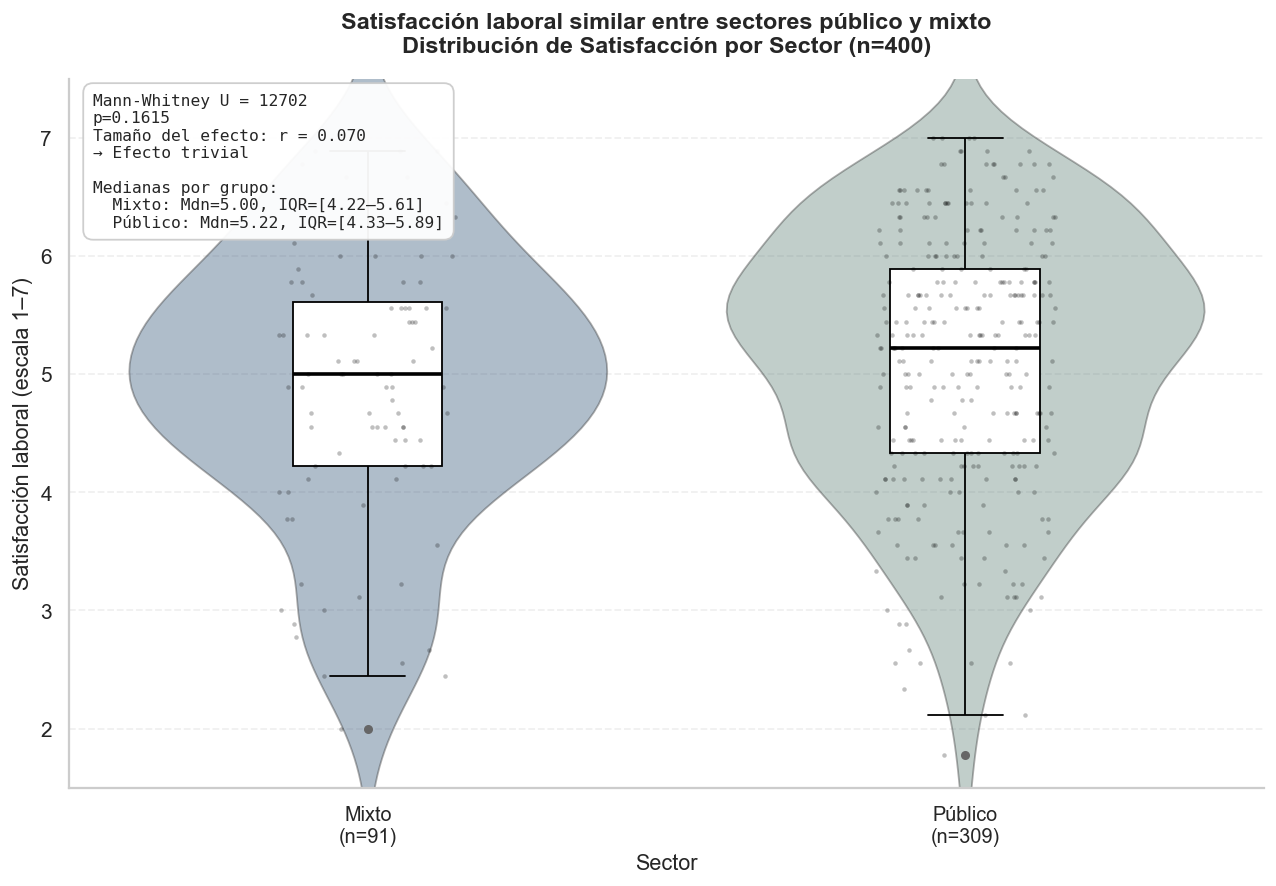

In [45]:
# COMPARACIÓN 2 - Satisfacción laboral por Sector
grupo, medida = 'Sector', 'SAT_prom'

orden = df.groupby(grupo)[medida].median().sort_values().index.tolist()
n_grupos = df.groupby(grupo).size()
etiquetas_x = [f'{g}\n(n={n_grupos[g]})' for g in orden]

# Mann-Whitney U (no paramétrico, 2 grupos)
g1 = df[df[grupo] == orden[0]][medida].values
g2 = df[df[grupo] == orden[1]][medida].values
U, p_mw = stats.mannwhitneyu(g1, g2, alternative='two-sided')

# Tamaño del efecto r = |Z|/√N
n1, n2 = len(g1), len(g2)
n_total = n1 + n2
mu_U = n1 * n2 / 2
sigma_U = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
Z = (U - mu_U) / sigma_U
r_efecto = abs(Z) / np.sqrt(n_total)
interp_efecto = ('Efecto grande' if r_efecto >= 0.5 else 'Efecto moderado'
                 if r_efecto >= 0.3 else 'Efecto pequeño' if r_efecto >= 0.1
                 else 'Efecto trivial')

fig, ax = plt.subplots(figsize=(10, 7))
paleta = ['#2E5A87', '#5E8B7E']
sns.violinplot(data=df, x=grupo, y=medida, order=orden, palette=paleta,
               inner=None, linewidth=1, alpha=0.4, ax=ax)
sns.boxplot(data=df, x=grupo, y=medida, order=orden, width=0.25,
            boxprops={'facecolor': 'white', 'edgecolor': 'black'},
            medianprops={'color': 'black', 'linewidth': 2},
            whiskerprops={'color': 'black'}, capprops={'color': 'black'},
            flierprops={'marker': 'o', 'markersize': 4,
                        'markerfacecolor': '#666', 'markeredgecolor': '#666'}, ax=ax)
sns.stripplot(data=df, x=grupo, y=medida, order=orden, color='black',
              alpha=0.25, size=2.5, jitter=0.15, ax=ax)

_ = ax.set_xticklabels(etiquetas_x, fontsize=11)
ax.set_xlabel('Sector', fontsize=12)
ax.set_ylabel('Satisfacción laboral (escala 1–7)', fontsize=12)

medianas = df.groupby(grupo)[medida].median()
q1 = df.groupby(grupo)[medida].quantile(0.25)
q3 = df.groupby(grupo)[medida].quantile(0.75)
linea_medianas = '\n'.join([f'  {g}: Mdn={medianas[g]:.2f}, IQR=[{q1[g]:.2f}–{q3[g]:.2f}]'
                            for g in orden])
p_str = 'p<0.001' if p_mw < 0.001 else f'p={p_mw:.4f}'

texto_stats = (f'Mann-Whitney U = {U:.0f}\n{p_str}\n'
               f'Tamaño del efecto: r = {r_efecto:.3f}\n→ {interp_efecto}\n\n'
               f'Medianas por grupo:\n{linea_medianas}')
ax.text(0.02, 0.98, texto_stats, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_title('Satisfacción laboral similar entre sectores público y mixto\n'
             f'Distribución de Satisfacción por Sector (n={n_total})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(1.5, 7.5)
plt.tight_layout()
plt.show()

**No hay diferencias significativas entre los sectores Público y Mixto** (U = 12702, p = 0.162; r ≈ 0.07, efecto trivial). Las distribuciones y medianas son muy similares.

**Implicación:** La satisfacción depende más de factores intra-organizacionales (liderazgo, claridad de rol, apoyo) que del tipo de empleador. Las intervenciones no requieren estrategias diferenciadas por sector.

**Cautela:** La muestra solo incluye dos sectores y los grupos son desbalanceados (309 vs 91).

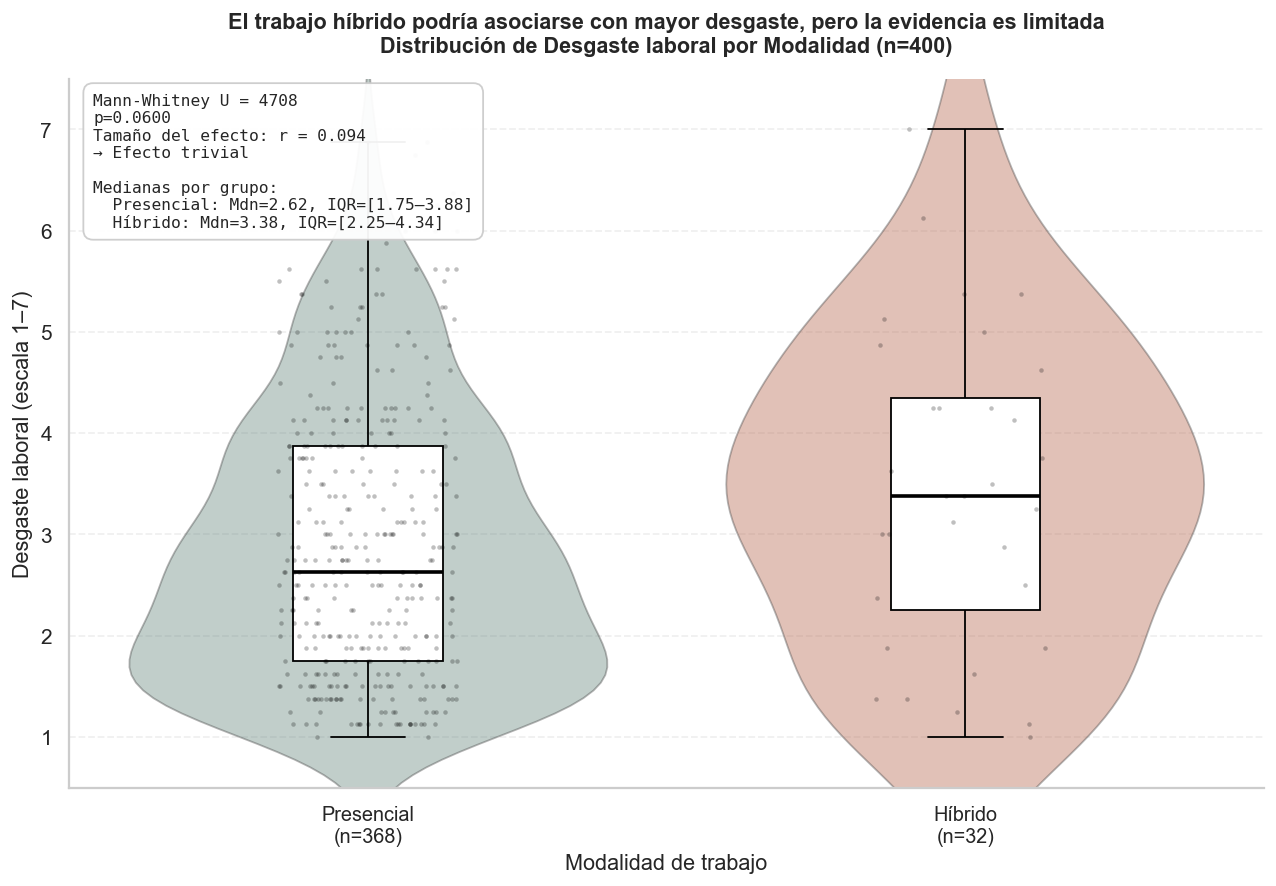

In [46]:
# COMPARACIÓN 3 - Desgaste laboral por Modalidad
grupo, medida = 'Modalidad', 'DL_prom'

orden = df.groupby(grupo)[medida].median().sort_values().index.tolist()
n_grupos = df.groupby(grupo).size()
etiquetas_x = [f'{g}\n(n={n_grupos[g]})' for g in orden]

g1 = df[df[grupo] == orden[0]][medida].values
g2 = df[df[grupo] == orden[1]][medida].values
U, p_mw = stats.mannwhitneyu(g1, g2, alternative='two-sided')

n1, n2 = len(g1), len(g2)
n_total = n1 + n2
mu_U = n1 * n2 / 2
sigma_U = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
Z = (U - mu_U) / sigma_U
r_efecto = abs(Z) / np.sqrt(n_total)
interp_efecto = ('Efecto grande' if r_efecto >= 0.5 else 'Efecto moderado'
                 if r_efecto >= 0.3 else 'Efecto pequeño' if r_efecto >= 0.1
                 else 'Efecto trivial')

fig, ax = plt.subplots(figsize=(10, 7))
paleta = ['#5E8B7E', '#C75B3C']
sns.violinplot(data=df, x=grupo, y=medida, order=orden, palette=paleta,
               inner=None, linewidth=1, alpha=0.4, ax=ax)
sns.boxplot(data=df, x=grupo, y=medida, order=orden, width=0.25,
            boxprops={'facecolor': 'white', 'edgecolor': 'black'},
            medianprops={'color': 'black', 'linewidth': 2},
            whiskerprops={'color': 'black'}, capprops={'color': 'black'},
            flierprops={'marker': 'o', 'markersize': 4,
                        'markerfacecolor': '#666', 'markeredgecolor': '#666'}, ax=ax)
sns.stripplot(data=df, x=grupo, y=medida, order=orden, color='black',
              alpha=0.25, size=2.5, jitter=0.15, ax=ax)

_ = ax.set_xticklabels(etiquetas_x, fontsize=11)
ax.set_xlabel('Modalidad de trabajo', fontsize=12)
ax.set_ylabel('Desgaste laboral (escala 1–7)', fontsize=12)

medianas = df.groupby(grupo)[medida].median()
q1 = df.groupby(grupo)[medida].quantile(0.25)
q3 = df.groupby(grupo)[medida].quantile(0.75)
linea_medianas = '\n'.join([f'  {g}: Mdn={medianas[g]:.2f}, IQR=[{q1[g]:.2f}–{q3[g]:.2f}]'
                            for g in orden])
p_str = 'p<0.001' if p_mw < 0.001 else f'p={p_mw:.4f}'

texto_stats = (f'Mann-Whitney U = {U:.0f}\n{p_str}\n'
               f'Tamaño del efecto: r = {r_efecto:.3f}\n→ {interp_efecto}\n\n'
               f'Medianas por grupo:\n{linea_medianas}')
ax.text(0.02, 0.98, texto_stats, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_title('El trabajo híbrido podría asociarse con mayor desgaste, pero la evidencia es limitada\n'
             f'Distribución de Desgaste laboral por Modalidad (n={n_total})',
             fontsize=12, fontweight='bold', pad=15)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0.5, 7.5)
plt.tight_layout()
plt.show()

**Resultado no significativo pero sugerente** (p = 0.060; efecto trivial). Los trabajadores híbridos muestran mayor desgaste (Mdn = 3.38) que los presenciales (Mdn = 2.62), una diferencia de 0.76 puntos que podría ser relevante en muestras más grandes.

**Implicación preliminar:** El trabajo híbrido no debe asumirse automáticamente como factor protector de bienestar; merece monitoreo específico.

**Cautela principal:** El grupo Híbrido tiene solo n = 32, lo que limita severamente la potencia estadística.

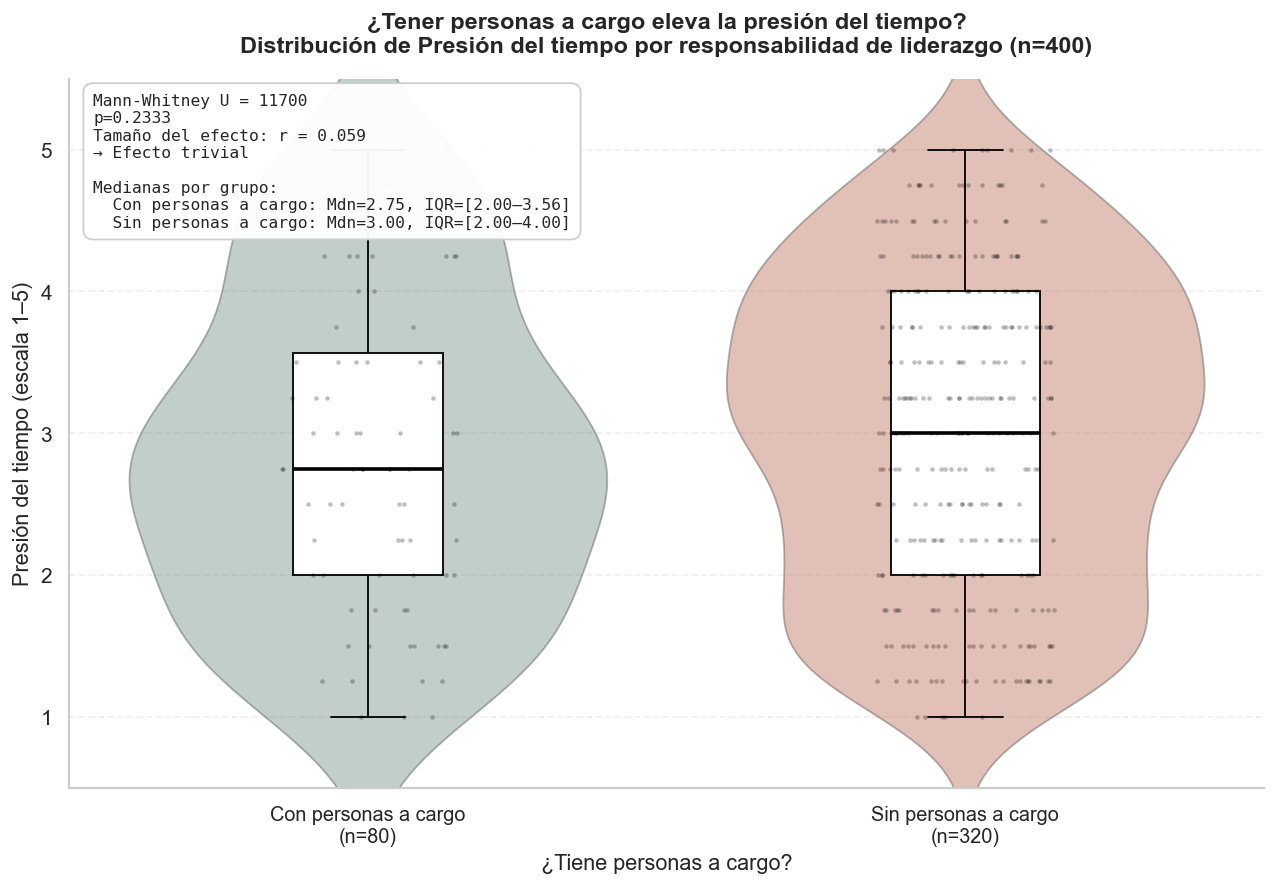

In [47]:
# COMPARACIÓN 4 - Presión del tiempo por responsabilidad de liderazgo
grupo, medida ='Personas_Cargo', 'PT_prom'

orden = df.groupby(grupo)[medida].median().sort_values().index.tolist()
n_grupos = df.groupby(grupo).size()
etiquetas_grupo = {'No': 'Sin personas a cargo', 'Si': 'Con personas a cargo'}
etiquetas_x = [f'{etiquetas_grupo.get(g, g)}\n(n={n_grupos[g]})' for g in orden]

g1 = df[df[grupo] == orden[0]][medida].values
g2 = df[df[grupo] == orden[1]][medida].values
U, p_mw = stats.mannwhitneyu(g1, g2, alternative='two-sided')

n1, n2 = len(g1), len(g2)
n_total = n1 + n2
mu_U = n1 * n2 / 2
sigma_U = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
Z = (U - mu_U) / sigma_U
r_efecto = abs(Z) / np.sqrt(n_total)
interp_efecto = ('Efecto grande' if r_efecto >= 0.5 else 'Efecto moderado'
                 if r_efecto >= 0.3 else 'Efecto pequeño' if r_efecto >= 0.1
                 else 'Efecto trivial')

fig, ax = plt.subplots(figsize=(10, 7))
paleta = ['#5E8B7E', '#C75B3C']
sns.violinplot(data=df, x=grupo, y=medida, order=orden, palette=paleta,
               inner=None, linewidth=1, alpha=0.4, ax=ax)
sns.boxplot(data=df, x=grupo, y=medida, order=orden, width=0.25,
            boxprops={'facecolor': 'white', 'edgecolor': 'black'},
            medianprops={'color': 'black', 'linewidth': 2},
            whiskerprops={'color': 'black'}, capprops={'color': 'black'},
            flierprops={'marker': 'o', 'markersize': 4,
                        'markerfacecolor': '#666', 'markeredgecolor': '#666'}, ax=ax)
sns.stripplot(data=df, x=grupo, y=medida, order=orden, color='black',
              alpha=0.25, size=2.5, jitter=0.15, ax=ax)

_ = ax.set_xticklabels(etiquetas_x, fontsize=11)
ax.set_xlabel('¿Tiene personas a cargo?', fontsize=12)
ax.set_ylabel('Presión del tiempo (escala 1–5)', fontsize=12)

medianas = df.groupby(grupo)[medida].median()
q1 = df.groupby(grupo)[medida].quantile(0.25)
q3 = df.groupby(grupo)[medida].quantile(0.75)
linea_medianas = '\n'.join([f'  {etiquetas_grupo.get(g, g)}: Mdn={medianas[g]:.2f}, '
                            f'IQR=[{q1[g]:.2f}–{q3[g]:.2f}]' for g in orden])
p_str = 'p<0.001' if p_mw < 0.001 else f'p={p_mw:.4f}'

texto_stats = (f'Mann-Whitney U = {U:.0f}\n{p_str}\n'
               f'Tamaño del efecto: r = {r_efecto:.3f}\n→ {interp_efecto}\n\n'
               f'Medianas por grupo:\n{linea_medianas}')
ax.text(0.02, 0.98, texto_stats, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                  edgecolor='#cccccc', alpha=0.95))

ax.set_title('¿Tener personas a cargo eleva la presión del tiempo?\n'
             f'Distribución de Presión del tiempo por responsabilidad de liderazgo (n={n_total})',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0.5, 5.5)
plt.tight_layout()
plt.show()

**Resultado no significativo y contraintuitivo** (p = 0.233; efecto trivial). Quienes tienen personas a cargo reportan presión del tiempo levemente *menor* (Mdn = 2.75) que quienes no la tienen (Mdn = 3.00).

**Hipótesis plausible:** La responsabilidad de liderazgo suele venir con mayor autonomía sobre la agenda, mientras que los roles operativos enfrentan plazos impuestos externamente.

**Implicación:** Las intervenciones de gestión del tiempo no deben concentrarse en niveles directivos; debe revisarse también la carga operativa y el grado de autonomía.

## **Sección 5 - Conclusiones y Recomendaciones**

### 5.1 Hallazgos principales

El análisis exploratorio de los 400 trabajadores arrojó cinco hallazgos centrales,
organizados según las preguntas orientadoras del proyecto:

**1. Perfil de la muestra.** El trabajador típico de esta población se desempeña en
el sector público, en un cargo administrativo, con formación profesional, contrato
de carrera o prestación de servicios, ingreso entre 1 y 3 SMLV y modalidad
presencial. Es un contexto institucional con alta rigidez contractual.

**2. Nivel de riesgo psicosocial generalizado pero no crítico.** Ninguna de las 16
dimensiones alcanza la categoría de riesgo *Muy alto*. Sin embargo, las tres
dimensiones de mayor riesgo *-Salud Mental organizacional, Control del trabajo y
Presión del tiempo-* se ubican en categoría *Alto* (IRE ≈ 49-52), lo que indica un
riesgo difuso que justifica intervención preventiva antes que correctiva.

**3. El sistema demanda-recurso opera como predice la teoría JD-R.** Las demandas
(presión del tiempo, conflictos de rol) correlacionan positivamente con las
dimensiones de desgaste (burnout, somatización, desgaste laboral), mientras que los
recursos (liderazgo, control) correlacionan negativamente con ellas. La presión del
tiempo predice el burnout de forma estrictamente lineal (ρ = +0.60).

**4. La satisfacción es el predictor más fuerte de la intención de retiro.** La
relación entre Satisfacción e Intención de Retiro (ρ = -0.83) es la más intensa de
todo el análisis: la insatisfacción anticipa el deseo de abandonar la organización.

**5. El bienestar no depende de la jerarquía ni del sector.** Ni el tipo de cargo,
ni el sector organizacional, ni la responsabilidad de liderazgo producen
diferencias significativas en los indicadores de bienestar. El agotamiento depende
del balance individual demandas-recursos, no de la posición en el organigrama. La
única señal de alerta diferencial es que la modalidad híbrida podría asociarse con mayor desgaste laboral.

### 5.2 Dimensiones de mayor riesgo

Aplicando los criterios técnicos de priorización (severidad del riesgo, influencia
sistémica sobre otras dimensiones y prevención de consecuencias), se identifican
**tres dimensiones de mayor urgencia de intervención**:

**1. Control del trabajo (CT) - Recurso, IRE ≈ 51.** Es el recurso más
deteriorado. Su prioridad no se basa solo en su puntaje: el control del trabajo
tiene **influencia sistémica**, ya que correlaciona fuertemente con la presión del
tiempo (ρ ≈ -0.78). Mejorar la autonomía de los trabajadores actúa como
amortiguador (*buffer*) frente a las demandas, con un efecto multiplicador sobre
varias dimensiones a la vez.

**2. Presión del tiempo (PT) - Demanda, IRE ≈ 50.** Es la demanda más elevada de la
muestra y un **antecedente directo del burnout** (ρ = +0.60, relación lineal). Es
una dimensión accionable: rediseñar cargas de trabajo y plazos tiene efecto medible
sobre el agotamiento.

**3. Salud Mental organizacional (SM) - Resultado, IRE ≈ 52.** Encabeza el ranking
de riesgo. Como dimensión de resultado, funciona como **termómetro del sistema**:
su deterioro confirma que las demandas elevadas y los recursos insuficientes ya
están produciendo consecuencias sobre el bienestar colectivo.

En conjunto, estas tres dimensiones reproducen la lógica del modelo JD-R: un
recurso debilitado (CT), una demanda intensa (PT) y un resultado comprometido (SM).
Intervenir sobre CT y PT es la vía más eficiente para mejorar SM, que es la consecuencia.

### 5.3 Recomendaciones organizacionales

Con base en la evidencia, se proponen las siguientes recomendaciones para la
organización cliente, priorizadas según las tres dimensiones críticas:

**Sobre el Control del trabajo (recurso a fortalecer).**
- Ampliar el margen de decisión de los trabajadores sobre el orden, el ritmo y el
  método de sus tareas, especialmente en cargos operativos y administrativos.
- Revisar procesos excesivamente normados que eliminan la autonomía sin aportar
  valor, dada la rigidez contractual característica del sector público.

**Sobre la Presión del tiempo (demanda a reducir).**
- Auditar la asignación de cargas de trabajo y la planificación de plazos para
  detectar sobrecarga estructural.
- Establecer plazos realistas y mecanismos de repriorización ante picos de demanda,
  en lugar de tratar la presión temporal como un costo inevitable.

**Sobre el liderazgo (recurso de alto retorno).**
- Invertir en desarrollo de mandos medios (formación, evaluación 360°, coaching):
  el compromiso del líder es un recurso protector frente al burnout (ρ = −0.52) y
  un antecedente de la satisfacción (ρ = +0.49).
- Tener presente que el liderazgo es necesario pero no suficiente: debe acompañarse
  de una estrategia integral de gestión humana.

**Sobre la retención del talento.**
- Usar la satisfacción laboral como **indicador anticipado de rotación**, dado su
  fuerte vínculo con la intención de retiro (ρ = −0.83). Monitorearla periódicamente
  permite anticipar la pérdida de capital intelectual.

**Sobre la modalidad de trabajo.**
- No asumir el trabajo híbrido como factor protector automático: la señal preliminar
  de mayor desgaste en este grupo justifica un monitoreo específico con una muestra
  mayor antes de tomar decisiones de política de modalidad.

**Recomendaciones transversales.**
- Diseñar las intervenciones de prevención de burnout **sin segmentar por jerarquía
  ni por sector**, ya que el bienestar no varía significativamente entre esos grupos;
  deben abordar las condiciones psicosociales que sí lo explican.

**Limitaciones del estudio.** El diseño es **transversal**, por lo que ninguna
relación puede interpretarse como causal. Todas
las dimensiones se miden por **autoreporte del mismo trabajador en el mismo momento**,
lo que infla parte de las correlaciones por varianza de método común. El agrupamiento
de dimensiones es exploratorio y su confirmación requeriría un análisis factorial
confirmatorio. Finalmente, algunos subgrupos (Híbrido n=32, Directivo n=35) tienen
tamaños muestrales pequeños que limitan la potencia estadística.